# One Box vs Two Boxes, Controlled

Six src6 boombox runs (`scripts/box_compare_four_objs_src6.sh`), all 2000 epochs, same recipe and seed. Every arm in a setting is scored on **exactly the same eval samples**: the held-out positions are identical in every arm.

| setting | arm | run | trains on |
|---|---|---|---|
| **spk137** (speaker- and sample-matched) | gastro | `s6-box-gastro-spk137-v1` | gastro, speakers 1,3,7 |
| | plastic | `s6-box-plastic-spk137-v1` | plastic, speakers 1,3,7 |
| | both | `s6-box-both-spk137-v1` | gastro + plastic, speakers 1,3,7 |
| **allspk** (all the data we have) | gastro | `s6-box-gastro-allspk-v1` | gastro, every speaker |
| | plastic | `s6-box-plastic-allspk-v1` | plastic, every speaker |
| | both | `s6-box-both-allspk-v1` | gastro + plastic, every speaker |

A single-box model is only scored on its own box, so each eval split has two models: the single-box model for that box, and `both`. Colors are fixed throughout: **gastro only = blue, plastic only = orange, both boxes = green**.

**How the models are matched.**
- **spk137 (section 4): equal training samples processed.** `both` has about 2.5x the training samples per epoch, so comparing at the same epoch would give it about 2.5x the training. All runs use batch 1024, so samples processed = optimizer steps x 1024. Each single-box model is scored at ep2000, the end of its run, and `both` at the saved epoch where it has processed the same number of samples. At that point `both` is mid-schedule (higher learning rate, not yet annealed), so if anything this is pessimistic for `both`.
- **allspk (section 5): the same epoch, ep2000.** Every run is scored at the end of its 2000-epoch schedule, fully annealed. `both` has seen more samples there (about 2x gastro's, 2.7x plastic's), so this asks "what does each full run end up as", not "what does a second box cost at equal compute".
- **Section 6** compares the two settings, so there every model is at its sample-matched point, in both settings.

**In distribution (ID)** means the held-out positions of `cube`, `candle`, `vase` and `soap-dispenser`. **Everything else is OOD**: two-object scenes, new objects, the moved lasers, and the unseen speaker.

No inference is run here. Everything comes from the masks each run saved during training (`outputs_history/eval`, every 100 epochs) and from the per-split metrics it logged (the same numbers as in wandb).

# 1 Setup

In [1]:
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

REPO = Path.cwd().parent
sys.path.insert(0, str(REPO))
from utils.metrics import _bin, _boundary, center_of_mass, contour_f, mass_error, object_centroids, soft_iou
from viz.data import load_gt

pd.set_option("display.width", 220, "display.max_columns", 80)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.axisbelow": True, "figure.dpi": 110})

SETTINGS = ("spk137", "allspk")
ARMS = ("gastro", "plastic", "both")
RUN = {(s, a): f"s6-box-{a}-{s}-v1" for s in SETTINGS for a in ARMS}
EXPS = {"gastro": "2026_09_27_gastronorm_four_objs", "plastic": "2026_10_05_green_plastic_four_objs"}
BOXES = tuple(EXPS)
COLOR = {"gastro": "#2a78d6", "plastic": "#eb6834", "both": "#1baf7a"}
LABEL = {"gastro": "gastro only", "plastic": "plastic only", "both": "both boxes"}
EPOCHS = 2000

# in distribution = held-out positions of the four single objects; everything else (two-object scenes, new objects,
# moved lasers, the unseen speaker, the extra cube captures) is out of distribution
ID = ["cube", "candle", "vase", "soap-dispenser"]
def kind(split): return "ID" if split in ID else "OOD"
# the three object groups each split-level bar plot is repeated for (moved lasers, unseen speaker and the extra cube
# captures are OOD but not new objects, so they only appear in the full plot)
MULTI = ["two-cubes", "cube-vase"]
NEW = ["coffee-pot", "cube-lid", "cylinder-100g", "cylinder-200g", "cylinder-500g", "cylinder-1000g", "portable-charger", "soap-dispenser-sideways"]
GROUPS = {"in distribution": ID, "OOD: two objects": MULTI, "OOD: new objects": NEW}
KINDS = ["ID", "OOD"]
SAMPLES_PER_STEP = 1024

def batches_per_epoch(run):
    last = max(int(m[1]) for l in open(REPO / "runs" / run / "logs-rank0.txt", errors="ignore") if (m := re.search(r"Train time/batch: (\d+)", l)))
    return (last + 1) // EPOCHS

BPE = {k: batches_per_epoch(r) for k, r in RUN.items()}
pd.DataFrame([dict(setting=s, arm=a, run=RUN[s, a], batches_per_epoch=BPE[s, a], steps=BPE[s, a] * EPOCHS,
                   samples_processed_M=BPE[s, a] * EPOCHS * SAMPLES_PER_STEP / 1e6) for s, a in RUN])

,setting,arm,run,batches_per_epoch,steps,samples_processed_M
0,spk137,gastro,s6-box-gastro-spk137-v1,2,4000,4.096
1,spk137,plastic,s6-box-plastic-spk137-v1,2,4000,4.096
2,spk137,both,s6-box-both-spk137-v1,5,10000,10.240
3,allspk,gastro,s6-box-gastro-allspk-v1,4,8000,8.192
4,allspk,plastic,s6-box-plastic-allspk-v1,3,6000,6.144
5,allspk,both,s6-box-both-allspk-v1,8,16000,16.384


**Sample-matched epoch for `both`** (used by spk137 and section 6; allspk compares everything at ep2000). For each box, `both` is scored at the saved epoch (a multiple of 100) where it has processed about as many training samples as that box's single-box run did in total:

- spk137: ep800 for both boxes (4.1M samples).
- allspk: ep1000 on gastro (8.2M samples). On plastic it is ep800 (6.6M vs plastic's 6.1M), because 750 was not saved.

In [2]:
def sample_matched(setting, box):
    # same batch size everywhere, so equal samples processed = equal steps
    target = BPE[setting, box] * EPOCHS
    return int(round(target / BPE[setting, "both"] / 100) * 100)

# how each setting's section compares the models: spk137 at equal training samples processed, allspk at the same epoch (ep2000,
# the end of every run). Section 6 compares the two settings, so it always uses the sample-matched view.
MATCH = {"spk137": "samples", "allspk": "epochs"}
SAMPLE_VIEWS = {(s, b): {b: EPOCHS, "both": sample_matched(s, b)} for s in SETTINGS for b in BOXES}
# (setting, box) -> {arm: epoch it is scored at}
VIEWS = {(s, b): v if MATCH[s] == "samples" else {b: EPOCHS, "both": EPOCHS} for (s, b), v in SAMPLE_VIEWS.items()}
pd.DataFrame([dict(setting=s, box=b, single_epoch=v[b], both_epoch=v["both"],
                   single_samples_M=BPE[s, b] * v[b] * SAMPLES_PER_STEP / 1e6,
                   both_samples_M=BPE[s, "both"] * v["both"] * SAMPLES_PER_STEP / 1e6) for (s, b), v in VIEWS.items()])

,setting,box,single_epoch,both_epoch,single_samples_M,both_samples_M
0,spk137,gastro,2000,800,4.096,4.096
1,spk137,plastic,2000,800,4.096,4.096
2,allspk,gastro,2000,2000,8.192,16.384
3,allspk,plastic,2000,2000,6.144,16.384


# 2 Per-Sample Scores

Each saved mask is joined to its 64x64 target and scored:

| column | meaning |
|---|---|
| `iou` | soft IoU, same as the logged metric |
| `paint` | **one number for too little vs too much**: `(sum pred - sum target) / (sum pred + sum target)`, in [-1, 1]. Negative means it paints too little, positive too much, 0 about right |
| `fuzz` | **confidence**: of the pixels the model paints at all (p > 0.1), the fraction it is unsure about (0.1 < p < 0.9). Lower = more confident |
| `peak` | highest pixel probability in the mask |
| `contour` | **edges**: boundary F-score, the fraction of each outline within 1 cell of the other's |
| `band` | **edge sharpness**: unsure pixels (0.1 < p < 0.9) per cell of true boundary, i.e. how many cells wide the blurry rim is. Lower = crisper edges |
| `com_px` | distance between predicted and true centre of mass, in 64-grid cells |
| `count_ok` | blobs in the thresholded prediction == number of objects |

Pixel calibration is also accumulated: for 10 probability bins, how often the target pixel is actually on.

In [3]:
GT = {b: load_gt(REPO / "experiments" / e, 64, 64) for b, e in EXPS.items()}
NOBJ = {b: {sid: m.get("n_objects", 0) for sid, m in zip(gt.sample_ids, gt.meta)} for b, gt in GT.items()}
BINS = np.linspace(0, 1, 11)

def sid_of(info, i):
    s = info["sample_id"][i]
    s = int(s.item() if torch.is_tensor(s) else s)
    return f"{s:06d}" if s >= 0 else f"{int(info['position_id'][i]):06d}-{int(info['speaker'][i])}"

def score(run, box, split, epoch):
    files = sorted((REPO / "runs" / run / "outputs_history" / "eval" / box / split).glob(f"ep{epoch:04d}-*.pt"))
    if not files: return None, None
    preds, sids, pos, spk = [], [], [], []
    for f in files:
        x = torch.load(f, weights_only=False)
        info = x["info"]
        preds.append(x["mask_pred"].float())
        sids += [sid_of(info, i) for i in range(len(x["mask_pred"]))]
        pos += torch.as_tensor(info["position_id"]).tolist(); spk += torch.as_tensor(info["speaker"]).tolist()
    p, gt = torch.cat(preds), GT[box]
    t = torch.from_numpy(np.stack([gt.masks[gt.row_of[s]] for s in sids]))
    unsure = ((p > 0.1) & (p < 0.9)).sum((-2, -1)).float()
    edge = _boundary(_bin(t)).sum((-2, -1)).clamp(min=1)
    df = pd.DataFrame(dict(box=box, split=split, kind=kind(split), epoch=epoch, sid=sids, position_id=pos, speaker=spk,
        n_true=[NOBJ[box][s] for s in sids], iou=soft_iou(p, t).numpy(), paint=mass_error(p, t).numpy(),
        fuzz=(unsure / (p > 0.1).sum((-2, -1)).clamp(min=1)).numpy(), peak=p.amax((-2, -1)).numpy(),
        contour=contour_f(p, t).numpy(), band=(unsure / edge).numpy(),
        com_px=(center_of_mass(p) - center_of_mass(t)).norm(dim=-1).numpy(),
        n_pred=[len(c) for c in object_centroids(p)]))
    df["count_ok"] = (df.n_pred == df.n_true).astype(float)
    b = np.clip(np.digitize(p.numpy().ravel(), BINS) - 1, 0, 9)
    cal = np.stack([np.bincount(b, minlength=10), np.bincount(b, weights=t.numpy().ravel(), minlength=10),
                    np.bincount(b, weights=p.numpy().ravel(), minlength=10)])
    return df, cal

def splits_of(run, box):
    d = REPO / "runs" / run / "outputs_history" / "eval" / box
    return sorted(x.name for x in d.iterdir()) if d.exists() else []

frames, CAL = [], {}
for s in SETTINGS:
    for a in ARMS:
        epochs = {EPOCHS} if a != "both" else {m["both"] for V in (VIEWS, SAMPLE_VIEWS) for (s_, b), m in V.items() if s_ == s}
        for b in (BOXES if a == "both" else (a,)):
            for split in splits_of(RUN[s, a], b):
                for e in sorted(epochs):
                    df, cal = score(RUN[s, a], b, split, e)
                    if df is None: continue
                    frames.append(df.assign(setting=s, arm=a))
                    CAL[s, a, b, e] = CAL.get((s, a, b, e), 0) + cal
per = pd.concat(frames, ignore_index=True)
per.to_parquet(REPO / "notebooks" / "runs" / "93_per_sample.parquet")
per.groupby(["setting", "arm", "box", "epoch"]).size().unstack("epoch")

epoch                      800     1000    2000
setting arm     box                            
allspk  both    gastro   1395.0  1395.0  1395.0
                plastic  1720.0  1720.0  1720.0
        gastro  gastro      NaN     NaN  1395.0
        plastic plastic     NaN     NaN  1720.0
spk137  both    gastro    956.0     NaN     NaN
                plastic  1395.0     NaN     NaN
        gastro  gastro      NaN     NaN   956.0
        plastic plastic     NaN     NaN  1395.0

Check that, within a setting, both models of a box were scored on the same samples. The split design guarantees this, and the cell asserts it.

In [4]:
key = ["box", "split", "position_id", "speaker"]
for s in SETTINGS:
    for b in BOXES:
        a = set(map(tuple, per[(per.setting == s) & (per.arm == b) & (per.box == b)][key].values))
        c = set(map(tuple, per[(per.setting == s) & (per.arm == "both") & (per.box == b) & (per.epoch == VIEWS[s, b]["both"])][key].values))
        assert a == c, (s, b, len(a ^ c))
        print(f"{s:7s} {b:8s} {len(a):5d} shared eval samples")

spk137  gastro     956 shared eval samples
spk137  plastic   1395 shared eval samples
allspk  gastro    1395 shared eval samples
allspk  plastic   1720 shared eval samples


# 3 Shared Helpers

In [5]:
rng = np.random.default_rng(0)

def pick(setting, box, arm, views=None):
    # rows for one model on one box, at the epoch its setting is compared at (VIEWS), or at `views`
    a = box if arm == "single" else "both"
    e = (views or VIEWS)[setting, box][a]
    return per[(per.setting == setting) & (per.box == box) & (per.arm == a) & (per.epoch == e)]

def matched(setting, views=None):
    # every row of the comparison: each single-box model on its box + both on each box, at VIEWS (or `views`)
    return pd.concat([pick(setting, b, m, views).assign(model=m) for b in BOXES for m in ("single", "both")], ignore_index=True)

def split_order(setting, box):
    s = per[(per.setting == setting) & (per.box == box)].split.unique()
    return sorted(s, key=lambda x: (KINDS.index(kind(x)), x))

# bar encoding: color = which model (blue gastro only, orange plastic only, green both boxes),
# stripes = which box's eval set (plastic striped, gastro solid)
HATCH = {"gastro": None, "plastic": "///"}
def bar_style(box, model):
    return dict(facecolor=COLOR[box] if model == "single" else COLOR["both"], hatch=HATCH[box], edgecolor="white", linewidth=0.5)
def bar_label(box, model): return f"{LABEL[box]}" if model == "single" else f"both boxes, {box} subset"
ERR = dict(fmt="none", ecolor="#52514e", lw=1, capsize=2)

def pos_stats(rows, metric):
    # mean and std over positions (speakers at one position share a target, so a position is one unit)
    v = rows.groupby(["split", "position_id"])[metric].mean()
    return v.mean(), v.std()

def boot_ci(v, n=400):
    v = np.asarray(v)
    if len(v) < 2: return (np.nan, np.nan)
    m = rng.choice(v, (n, len(v))).mean(1)
    return np.percentile(m, 2.5), np.percentile(m, 97.5)

def paired(setting, box, metric):
    # both - single per sample, averaged per position (speakers at one position share a target)
    s = pick(setting, box, "single").set_index(key)[metric]
    b = pick(setting, box, "both").set_index(key)[metric]
    d = (b - s).rename("d").reset_index()
    return d.groupby(["split", "position_id"]).d.mean().reset_index()

def delta_table(setting, metric):
    rows = []
    for box in BOXES:
        d = paired(setting, box, metric)
        for split, g in d.groupby("split"):
            lo, hi = boot_ci(g.d)
            s = pick(setting, box, "single"); s = s[s.split == split][metric].mean()
            rows.append(dict(box=box, split=split, kind=kind(split), single=s, both=s + g.d.mean(), d=g.d.mean(), lo=lo, hi=hi, n_pos=len(g)))
    return pd.DataFrame(rows)

def by_kind(setting, metric):
    # average per split first, then across splits, so the big ID splits don't drown the small OOD ones
    t = delta_table(setting, metric)
    return t.groupby(["box", "kind"])[["single", "both", "d"]].mean().reindex([(b, k) for b in BOXES for k in KINDS]).dropna(how="all")

**Combined view.** One chart per setting for the objects both boxes have. For each object there are two pairs: on the gastro eval set, **gastro only** next to **both**, and on the plastic eval set, **plastic only** next to **both** (hatched). Error bars are 95% bootstrap intervals over positions.

In [6]:
def combined_plot(setting, metric="iou", ylabel="soft IoU", ylim=(0, 1)):
    # the full plot, then one per object group
    _combined_plot(setting, None, "all objects in both boxes", metric, ylabel, ylim)
    for name, splits in GROUPS.items(): _combined_plot(setting, splits, name, metric, ylabel, ylim)

def _combined_plot(setting, only, name, metric, ylabel, ylim):
    shared = [s for s in split_order(setting, "gastro") if s in set(split_order(setting, "plastic")) and (only is None or s in only)]
    fig, ax = plt.subplots(figsize=(max(9, 1.15 * len(shared)), 4.3))
    w = 0.2
    for i, split in enumerate(shared):
        for j, (box, arm) in enumerate([("gastro", "single"), ("gastro", "both"), ("plastic", "single"), ("plastic", "both")]):
            r = pick(setting, box, arm); m, sd = pos_stats(r[r.split == split], metric)
            x = i + (j - 1.5) * w + (0.04 if j >= 2 else -0.04)
            ax.bar(x, m, w * 0.92, **bar_style(box, arm))
            ax.errorbar(x, m, yerr=sd, **ERR)
    ax.set_xticks(range(len(shared)), shared, rotation=35, ha="right")
    for i, s in enumerate(shared):
        if kind(s) != "ID": ax.get_xticklabels()[i].set_color("#8a8984")
    n_id = sum(kind(s) == "ID" for s in shared)
    if 0 < n_id < len(shared): ax.axvline(n_id - 0.5, color="#52514e", lw=1, ls=":")
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(**bar_style(b, m), label=f"{bar_label(b, m)} ({b} eval)") for b in BOXES for m in ("single", "both")],
              frameon=False, fontsize=8, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.02), handlelength=3, handleheight=1.6,
              title="solid = gastro eval, striped = plastic eval; bars = mean +- std over positions", title_fontsize=8)
    ax.set_ylabel(ylabel)
    if ylim: ax.set_ylim(*ylim)
    eps = {b: f"ep{VIEWS[setting, b]['both']}" for b in BOXES}
    ax.set_title(f"{setting}, {name} (single at ep2000, both at {eps}: matched samples)", fontsize=10, pad=62)
    fig.tight_layout(); plt.show()

def per_box_plot(setting, metric="iou", ylabel="soft IoU", ylim=(0, 1)):
    # the full plot, then one per object group
    _per_box_plot(setting, None, "all splits", metric, ylabel, ylim)
    for name, splits in GROUPS.items(): _per_box_plot(setting, splits, name, metric, ylabel, ylim)

def _per_box_plot(setting, only, name, metric, ylabel, ylim):
    # one panel per box, every split: the single-box model vs the subset of `both` scored on that box
    n = max(len([sp for sp in split_order(setting, b) if only is None or sp in only]) for b in BOXES)
    fig, axes = plt.subplots(2, 1, figsize=(max(7, 0.85 * n + 2), 8.5 if only is None else 6.5))
    for ax, box in zip(axes, BOXES):
        order = [sp for sp in split_order(setting, box) if only is None or sp in only]
        for j, arm in enumerate(["single", "both"]):
            r = pick(setting, box, arm)
            m, sd = zip(*[pos_stats(r[r.split == split], metric) for split in order])
            x = np.arange(len(order)) + (j - 0.5) * 0.4
            ax.bar(x, m, 0.37, **bar_style(box, arm), label=f"{bar_label(box, arm)} (ep{VIEWS[setting, box][box if arm == 'single' else 'both']})")
            ax.errorbar(x, m, yerr=sd, **ERR)
        ax.set_xticks(range(len(order)), order, rotation=30, ha="right", fontsize=8)
        for i, sp in enumerate(order):
            if kind(sp) != "ID": ax.get_xticklabels()[i].set_color("#8a8984")
        n_id = sum(kind(sp) == "ID" for sp in order)
        if 0 < n_id < len(order): ax.axvline(n_id - 0.5, color="#52514e", lw=1, ls=":")
        ax.set_ylabel(ylabel); ax.set_ylim(*ylim); ax.legend(frameon=False, fontsize=8, loc="upper right")
        ax.set_title(f"{box} eval: {LABEL[box]} vs the {box} subset of both boxes", fontsize=10)
    fig.suptitle(f"{setting}, {name}: matched samples; mean +- std over positions" + (" (left of the dotted line = in distribution)" if only is None else ""), y=1.0)
    fig.tight_layout(); plt.show()

def four_bars(setting, metric="iou"):
    # headline: gastro only | both on gastro | plastic only | both on plastic, averaged over splits of each kind
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    for ax, k in zip(axes, KINDS):
        vals, sds, labs = [], [], []
        x = np.array([0, 1, 2.6, 3.6])
        for xi, (box, arm) in zip(x, [(b, a) for b in BOXES for a in ("single", "both")]):
            r = pick(setting, box, arm); r = r[r.kind == k]
            v = r.groupby("split")[metric].mean().mean()         # mean over splits, so big splits don't dominate
            sd = r.groupby(["split", "position_id"])[metric].mean().std()
            ax.bar(xi, v, 0.85, **bar_style(box, arm)); ax.errorbar(xi, v, yerr=sd, **ERR)
            vals.append(v); sds.append(sd); labs.append(f"{LABEL[box]}\n({box} eval)" if arm == "single" else f"both boxes\n({box} subset)")
        for xi, v in zip(x, vals): ax.text(xi + 0.08, v + 0.01, f"{v:.3f}", ha="left", va="bottom", fontsize=8)
        for a, b in [(0, 1), (2, 3)]:
            ax.text((x[a] + x[b]) / 2, max(vals[a] + sds[a], vals[b] + sds[b]) + 0.04, f"{vals[b] - vals[a]:+.3f}", ha="center", fontsize=9, color="#0b0b0b")
        ax.set_xticks(x, labs, fontsize=8); ax.set_title(f"{k} splits (mean over splits)", fontsize=10)
    axes[0].set_ylabel(f"mean {metric}")
    fig.suptitle(f"{setting}: each box's score from its own model vs from the shared model (matched samples; +- std over positions; striped = plastic)", y=1.02)
    fig.tight_layout(); plt.show()

def delta_plot(setting, metric, xlabel):
    # both - single per split, sample-matched, with a 95% CI over positions
    fig, axes = plt.subplots(1, 2, figsize=(14, 0.32 * max(len(split_order(setting, b)) for b in BOXES) + 1.8), sharex=True)
    for ax, box in zip(axes, BOXES):
        order = split_order(setting, box)[::-1]
        t = delta_table(setting, metric).query("box == @box").set_index("split").reindex(order)
        y = np.arange(len(order))
        c = [COLOR["both"] if kind(sp) == "ID" else "#52514e" for sp in order]
        ax.errorbar(t.d, y, xerr=[t.d - t.lo, t.hi - t.d], fmt="none", ecolor="#c3c2b7", elinewidth=1)
        ax.scatter(t.d, y, color=c, s=30, zorder=3)
        ax.axvline(0, color="#52514e", lw=1)
        ax.set_yticks(range(len(order)), [f"{s}  [{kind(s)}]" for s in order], fontsize=8)
        ax.set_title(f"{box} eval: both (ep{VIEWS[setting, box]['both']}) - {box} only (ep2000)"); ax.set_xlabel(xlabel)
    fig.suptitle(f"{setting}, matched samples (green = ID, gray = OOD)", y=1.0); fig.tight_layout(); plt.show()

def kind_bars(setting, metrics):
    fig, axes = plt.subplots(1, len(metrics), figsize=(4.2 * len(metrics), 3.6))
    for ax, (metric, label) in zip(np.atleast_1d(axes), metrics):
        t = by_kind(setting, metric)
        x = np.arange(len(t))
        for i, (box, k) in enumerate(t.index):
            for j, model in enumerate(("single", "both")):
                r = pick(setting, box, model); sd = r[r.kind == k].groupby(["split", "position_id"])[metric].mean().std()
                ax.bar(i + (j - 0.5) * 0.4, t.loc[(box, k), model], 0.38, **bar_style(box, model))
                ax.errorbar(i + (j - 0.5) * 0.4, t.loc[(box, k), model], yerr=sd, **ERR)
            ax.text(i + 0.2, t.loc[(box, k), "both"], f" {t.loc[(box, k), 'd']:+.3f}", ha="left", va="bottom", fontsize=7)
        ax.set_xticks(x, [f"{b}\n{k}" for b, k in t.index], fontsize=7)
        ax.set_title(label, fontsize=10)
    from matplotlib.patches import Patch
    np.atleast_1d(axes)[0].legend(handles=[Patch(**bar_style(b, m), label=bar_label(b, m)) for b in BOXES for m in ("single", "both")],
                                  frameon=False, fontsize=7, handlelength=3, handleheight=1.6)
    fig.suptitle(f"{setting}, matched samples (mean over splits, +- std over positions; striped = plastic)", y=1.02); fig.tight_layout(); plt.show()

In [7]:
PAT = re.compile(r"^\[metric\]\[batch=(\d+)\]: metrics/(eval/(gastro|plastic)/([^/]+)|train)/(\w+): ([-\d.eE+na]+)")
def parse_log(run):
    out = []
    for l in open(REPO / "runs" / run / "logs-rank0.txt", errors="ignore"):
        if l.startswith("[metric]") and (m := PAT.match(l)):
            out.append((int(m[1]), m[3] or "train", m[4] or "train", m[5], float(m[6])))
    return pd.DataFrame(out, columns=["batch", "box", "split", "metric", "value"]).drop_duplicates(["batch", "box", "split", "metric"], keep="last")
LOGS = pd.concat([parse_log(RUN[k]).assign(setting=k[0], arm=k[1], samples=lambda d: d.batch * SAMPLES_PER_STEP / 1e6) for k in RUN], ignore_index=True)

def curves(setting):
    ev = LOGS[(LOGS.setting == setting) & (LOGS.metric == "iou") & (LOGS.box != "train")]
    ev = ev.assign(kind=ev.split.map(kind))
    fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
    for ax, box in zip(axes, BOXES):
        for arm in (box, "both"):
            e = ev[(ev.arm == arm) & (ev.box == box)]
            for k, ls in [("ID", "-"), ("OOD", "--")]:
                m = e[e.kind == k].groupby(["samples", "split"]).value.mean().unstack().mean(axis=1)
                ax.plot(m.index, m.values, ls, color=COLOR[arm], lw=2, label=f"{LABEL[arm]}, {k}")
        ax.axvline(BPE[setting, box] * EPOCHS * SAMPLES_PER_STEP / 1e6, color=COLOR[box], ls=":", lw=1)
        ax.set_title(f"{box} eval", fontsize=10); ax.set_xlabel("training samples processed (millions)"); ax.legend(frameon=False, fontsize=7)
    axes[0].set_ylabel("mean IoU over splits")
    fig.suptitle(f"{setting}: dotted line = where the single-box run ends (= the sample-matched point)", y=1.02); fig.tight_layout(); plt.show()

def reliability(setting):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
    for ax, box in zip(axes, BOXES):
        for arm in (box, "both"):
            c = CAL[setting, arm, box, VIEWS[setting, box][arm]]
            ok = c[0] > 0
            ax.plot(c[2][ok] / c[0][ok], c[1][ok] / c[0][ok], "o-", color=COLOR[arm], lw=2, ms=5, label=LABEL[arm])
            ece = np.abs(c[1] - c[2]).sum() / c[0].sum()
            ax.text(0.02, 0.92 - 0.07 * (arm == "both"), f"{LABEL[arm]} ECE {ece:.4f}", transform=ax.transAxes, fontsize=8, color="#0b0b0b")
        ax.plot([0, 1], [0, 1], color="#52514e", lw=1, ls=":")
        ax.set_xlabel("mean predicted probability in bin"); ax.set_ylabel("fraction of target pixels on")
        ax.set_title(f"{box} eval: pixel calibration", fontsize=10); ax.legend(frameon=False, fontsize=8, loc="lower right")
    fig.suptitle(f"{setting}, matched samples. Below the diagonal = over-confident, above = under-confident", y=1.02); fig.tight_layout(); plt.show()

def ece_table(setting):
    # expected calibration error (pixel-weighted |freq - conf|) and the share of pixels in the confident bins
    rows = []
    for box in BOXES:
        for arm in (box, "both"):
            c = CAL[setting, arm, box, VIEWS[setting, box][arm]]
            rows.append(dict(box=box, model=LABEL[arm], ece=np.abs(c[1] - c[2]).sum() / c[0].sum(),
                             over_conf=(c[2][-1] - c[1][-1]) / max(c[0][-1], 1), share_p_gt_0_9=c[0][-1] / c[0][1:].sum()))
    return pd.DataFrame(rows).round(4)

def paint_table(setting):
    # one number per object: mean signed paint error, single vs both
    t = delta_table(setting, "paint")
    return t.pivot_table(index=["kind", "split"], columns="box", values=["single", "both"]).round(3)

def label_points(ax, xs, ys, texts, fontsize=7):
    # label every point; nudge labels apart (in pixels) until no two boxes overlap, with a leader line when moved
    ax.figure.canvas.draw()
    P = ax.transData.transform(np.c_[xs, ys])
    px = fontsize * ax.figure.dpi / 72
    W = np.array([0.6 * px * len(t) for t in texts]); H = 1.25 * px
    L = P + np.array([0.6 * px, -0.4 * px])
    for _ in range(400):
        moved = False
        for i in range(len(L)):
            for j in range(i + 1, len(L)):
                if L[i, 0] < L[j, 0] + W[j] and L[j, 0] < L[i, 0] + W[i] and abs(L[i, 1] - L[j, 1]) < H:
                    sgn = 1 if L[j, 1] >= L[i, 1] else -1
                    L[j, 1] += sgn * 0.6; L[i, 1] -= sgn * 0.6; moved = True
        if not moved: break
    for (x, y), (lx, ly), t, d in zip(np.c_[xs, ys], L, texts, L - P):
        far = np.hypot(*(d - [0.6 * px, -0.4 * px])) > 0.5 * px
        ax.annotate(t, (x, y), xytext=tuple(d), textcoords="offset pixels", fontsize=fontsize, va="bottom", color="#0b0b0b",
                    arrowprops=dict(arrowstyle="-", color="#52514e", lw=0.8, shrinkA=0, shrinkB=4) if far else None)

def object_scatter(setting, metric="iou"):
    # the full plot, then one per object group (each group zoomed to its own range)
    _object_scatter(setting, None, "all splits", metric)
    for name, splits in GROUPS.items(): _object_scatter(setting, splits, name, metric)

def _object_scatter(setting, only, name, metric):
    # single-box score vs both score per split; above the diagonal = the second box helped (unseen-speaker splits left out)
    t = delta_table(setting, metric)
    t = t[~t.split.str.contains("unseen-speaker")]
    if only is not None: t = t[t.split.isin(only)]
    fig, ax = plt.subplots(figsize=(7, 7))
    vals = np.r_[t.single.values, t.both.values]
    if only is None: lo, hi = 0.0, vals.max() * 1.05
    else: pad = 0.08 * (vals.max() - vals.min()) + 0.01; lo, hi = max(0.0, vals.min() - pad), vals.max() + pad
    ax.plot([lo, hi], [lo, hi], color="#52514e", lw=1, ls=":", zorder=1)
    ax.fill_between([lo, hi], [lo, hi], hi, color=COLOR["both"], alpha=0.05, zorder=0)
    span = hi - lo
    ax.text(lo + 0.03 * span, lo + 0.95 * span, "above: both boxes better", fontsize=11, color="#52514e", va="top")
    ax.text(lo + 0.95 * span, lo + 0.03 * span, "below: single box better", fontsize=11, color="#52514e", ha="right")
    mk = {"ID": "o", "OOD": "^"}
    for (box, k), g in t.groupby(["box", "kind"]):
        # sqrt keeps the size order by positions without shrinking the ~8-position OOD splits to dots
        ax.scatter(g.single, g.both, s=140 + 45 * np.sqrt(g.n_pos), marker=mk[k], color=COLOR[box], alpha=0.85, edgecolor="white", label=f"{box} {k}", zorder=3)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
    label_points(ax, t.single.values, t.both.values, t.split.tolist(), fontsize=9)
    ax.set_xlabel(f"single-box {metric} (ep2000)", fontsize=12); ax.set_ylabel(f"both boxes {metric} (sample-matched)", fontsize=12)
    ax.tick_params(labelsize=10)
    ax.set_title(f"{setting}, {name}: single box vs both boxes\n(marker size = positions)", fontsize=12)
    ax.legend(frameon=False, fontsize=10, loc="lower right", bbox_to_anchor=(1, 0.07), markerscale=0.6); fig.tight_layout(); plt.show()

def object_gain(setting, metric="iou"):
    # which objects gain from the second box: per-split change against the single-box score (unseen-speaker splits left out)
    t = delta_table(setting, metric)
    t = t[~t.split.str.contains("unseen-speaker")]
    fig, ax = plt.subplots(figsize=(11, 7.5))
    mk = {"ID": "o", "OOD": "^"}
    for (box, k), g in t.groupby(["box", "kind"]):
        ax.scatter(g.single, g.d, s=20 + 4 * g.n_pos, marker=mk[k], color=COLOR[box], alpha=0.85, edgecolor="white", label=f"{box} {k}", zorder=3)
    ax.axhline(0, color="#52514e", lw=1)
    label_points(ax, t.single.values, t.d.values, t.split.tolist())
    ax.set_xlabel(f"single-box {metric}"); ax.set_ylabel(f"both - single {metric}")
    ax.set_title(f"{setting}: which objects gain from a second box (matched samples; marker size = positions)", fontsize=10)
    ax.legend(frameon=False, fontsize=7, ncol=2); fig.tight_layout(); plt.show()

# 4 Setting 1: speaker- and sample-matched (spk137)

## 4.1 Each box: its own model vs its subset of `both`
The `both` model's score splits into a gastro part and a plastic part. Each part is compared with the model trained on that box alone, first as one headline number per box, then split by split. Each split-level plot is drawn for all splits, then for three groups: **in distribution** (cube, candle, vase, soap-dispenser), **OOD: two objects** (two-cubes, cube-vase) and **OOD: new objects** (objects never trained on).

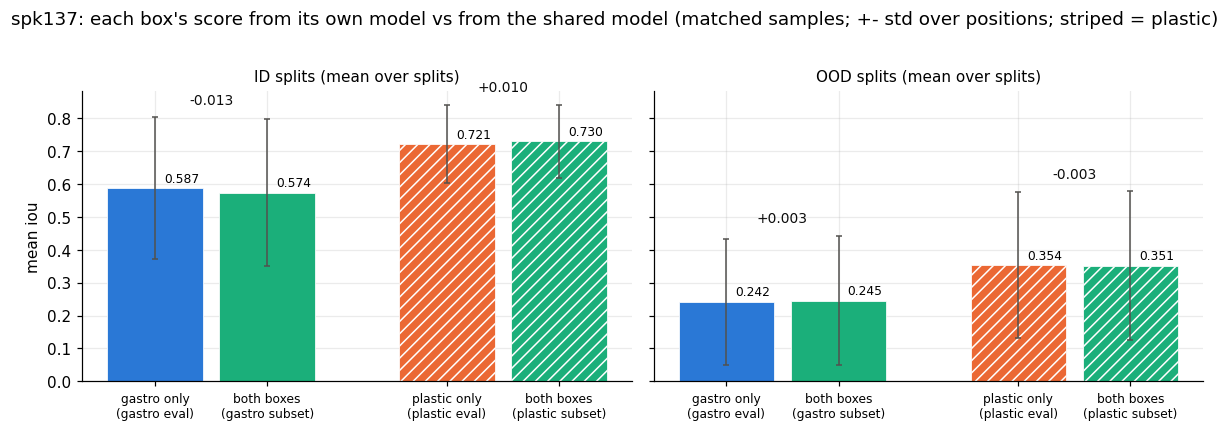

In [8]:
four_bars("spk137")

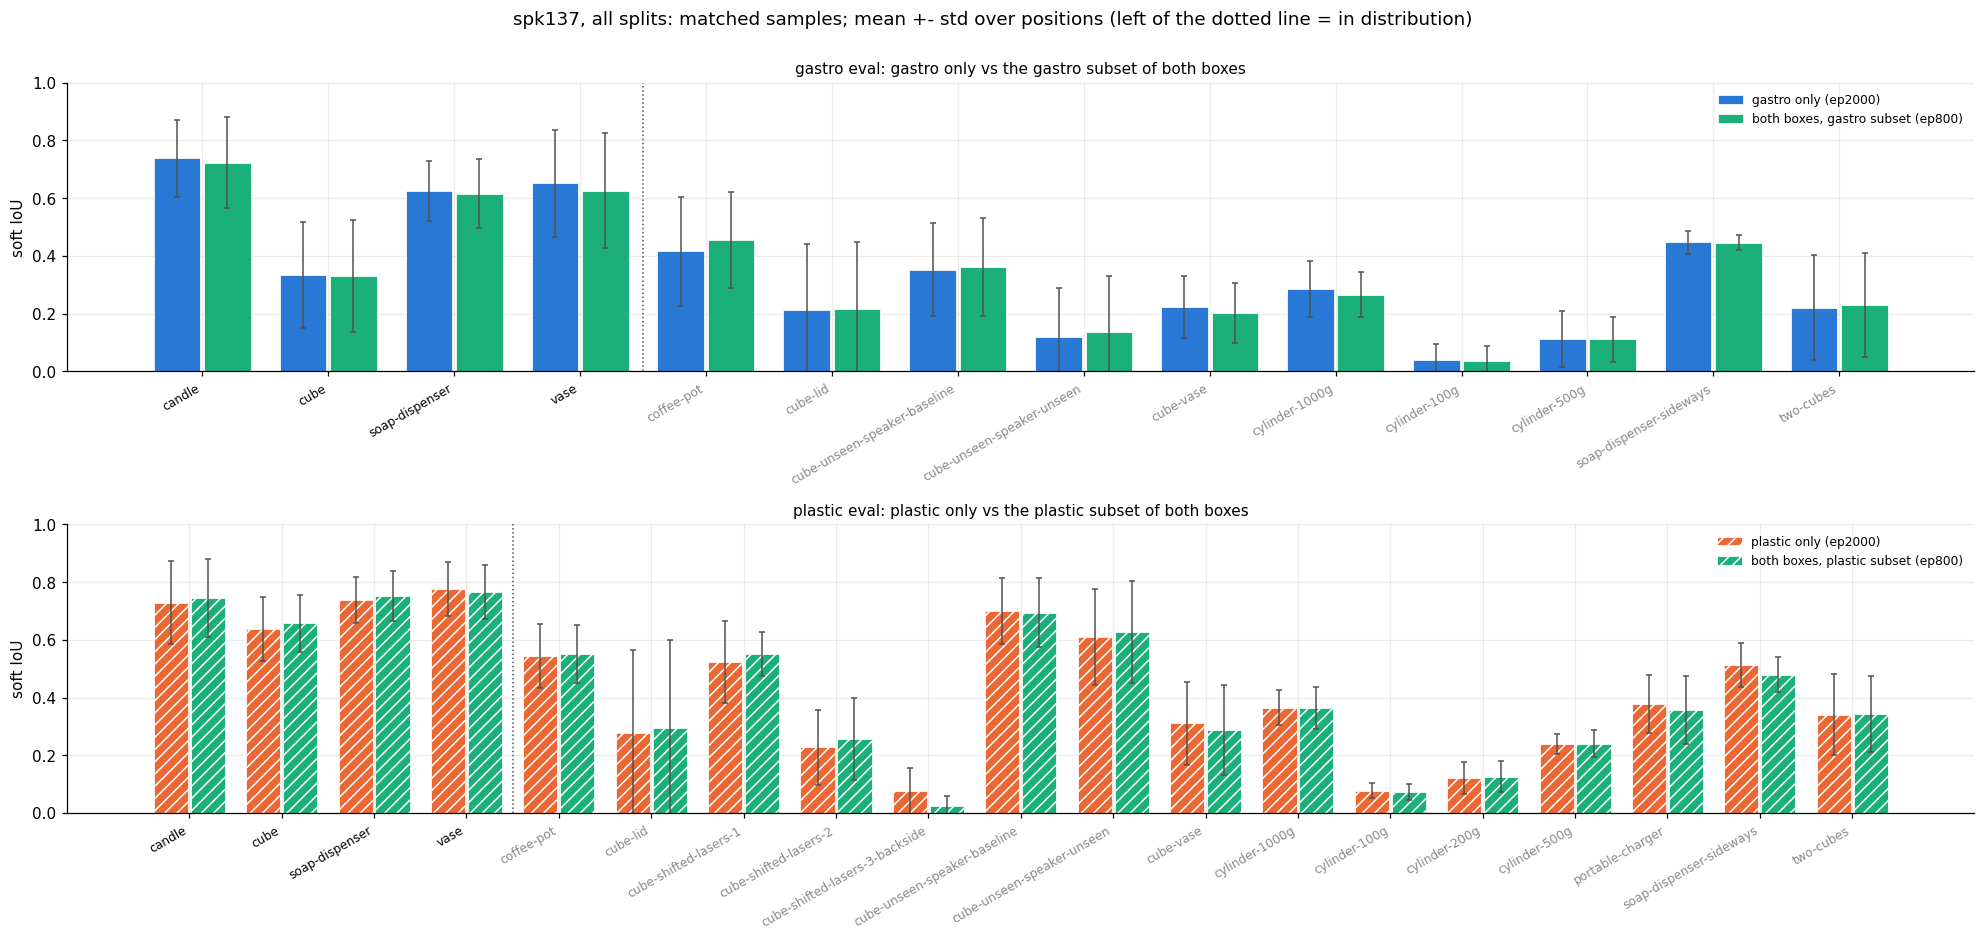

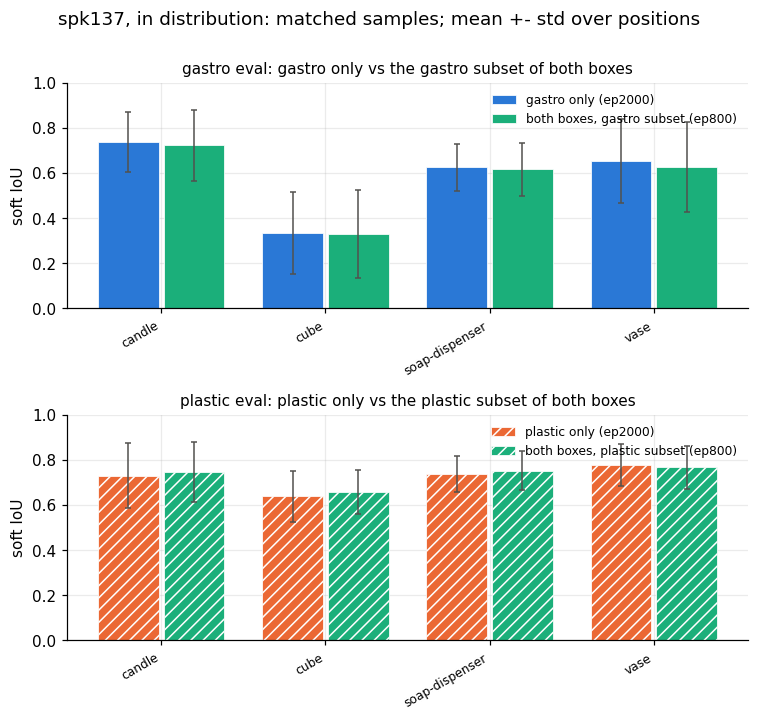

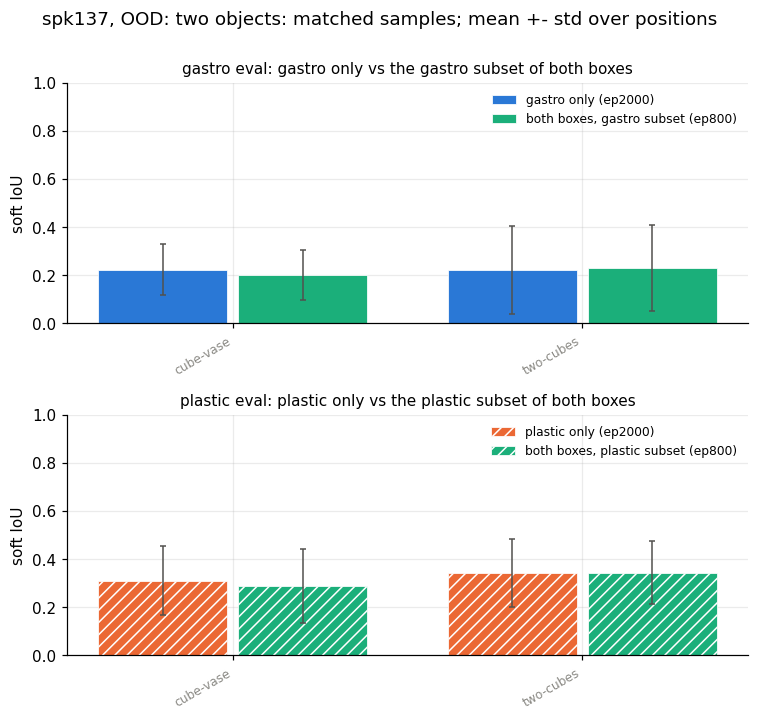

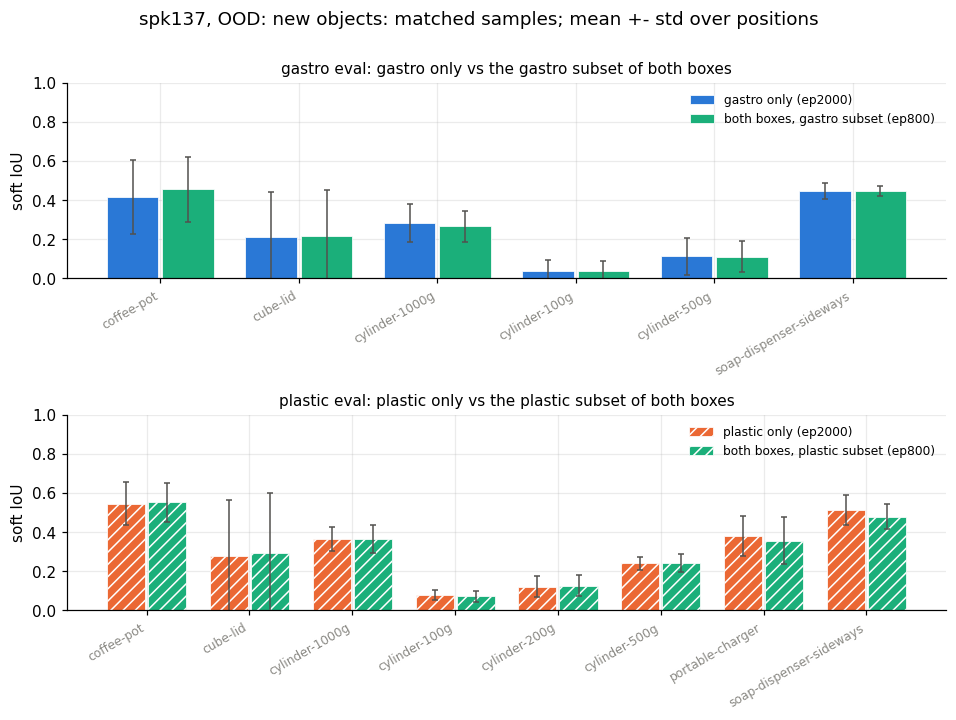

In [9]:
per_box_plot("spk137")

Same as above, but for the objects both boxes have, with all four bars side by side.

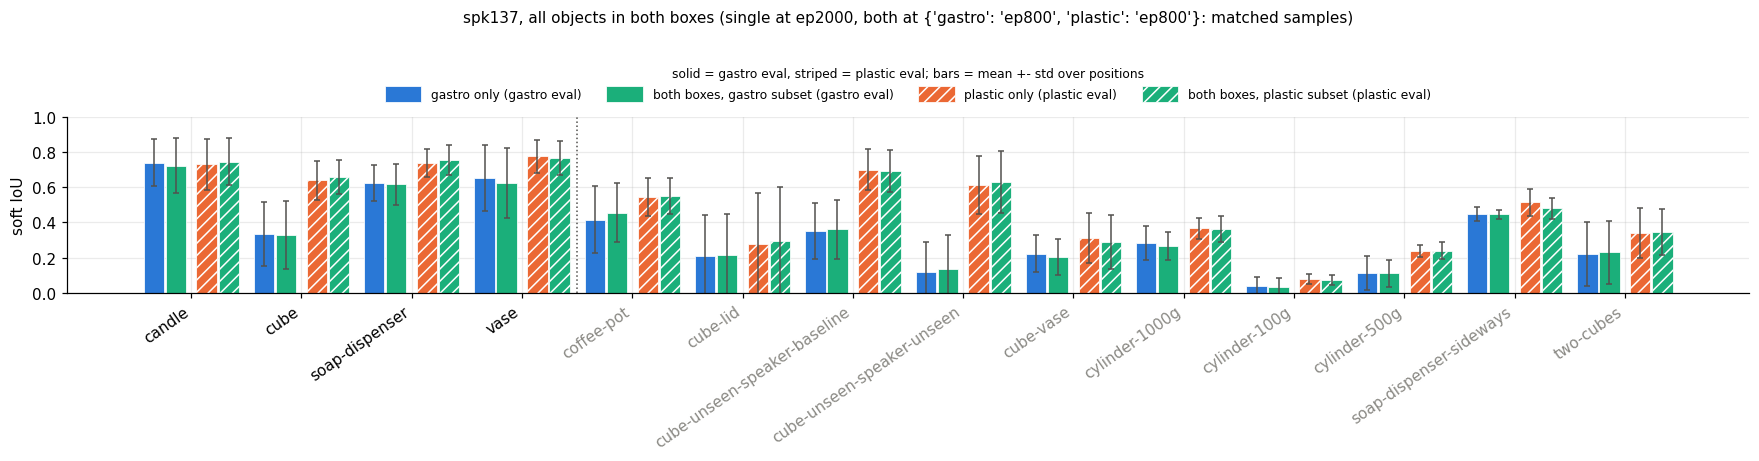

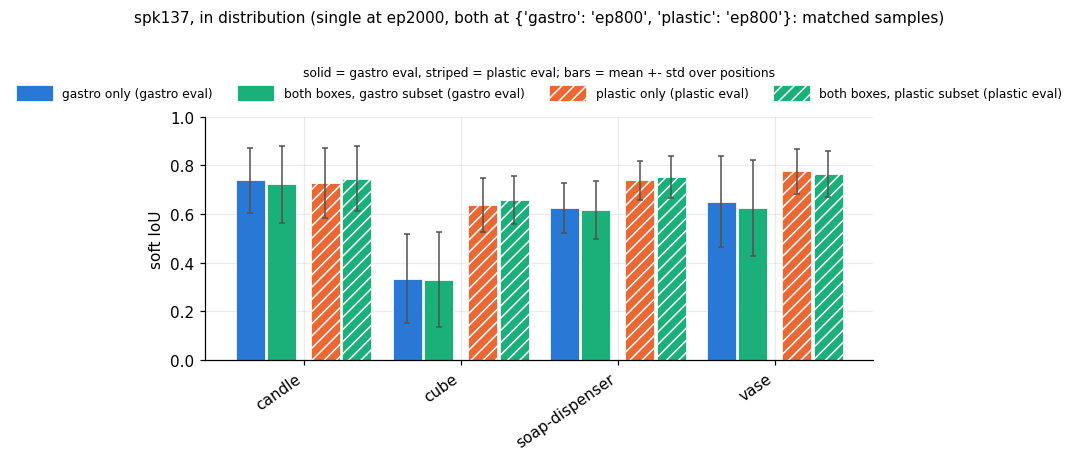

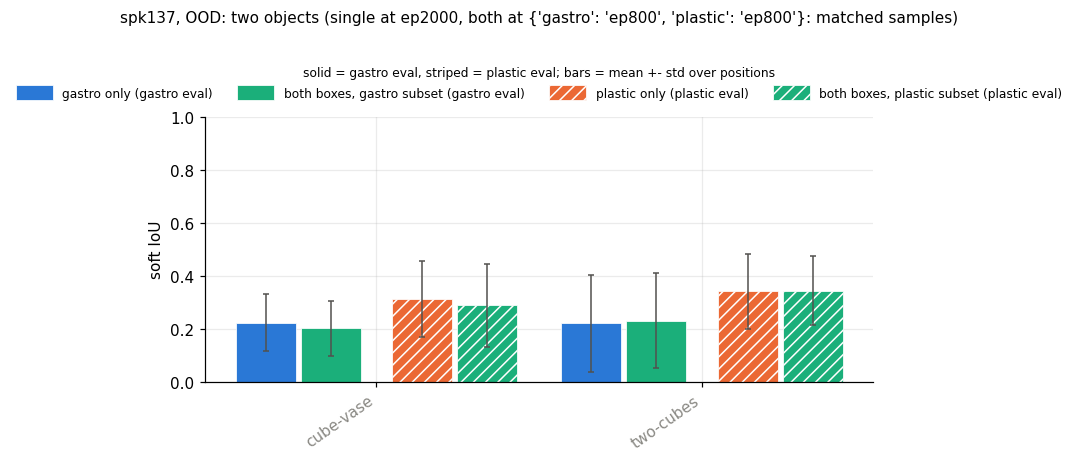

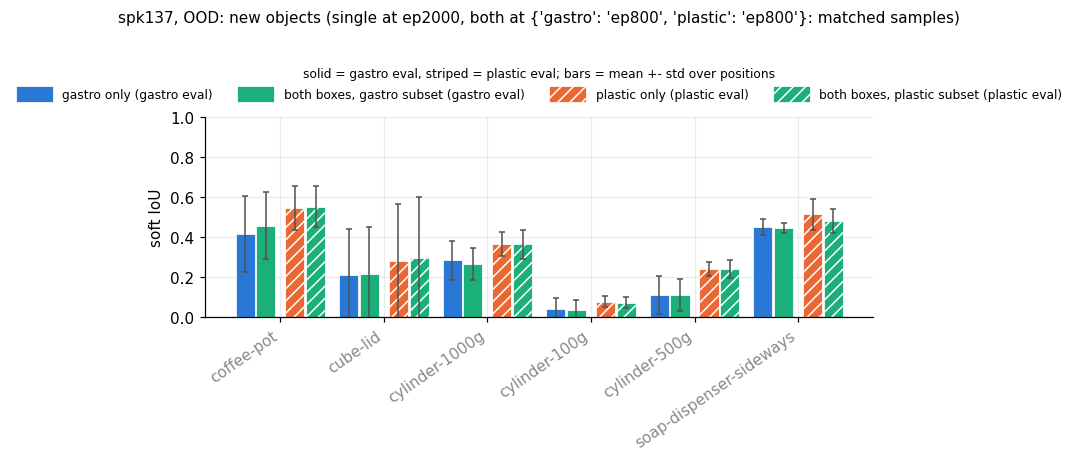

In [10]:
combined_plot("spk137")

## 4.2 Every split, as a difference
Each dot is `both - single` for one split, with a 95% CI over positions.

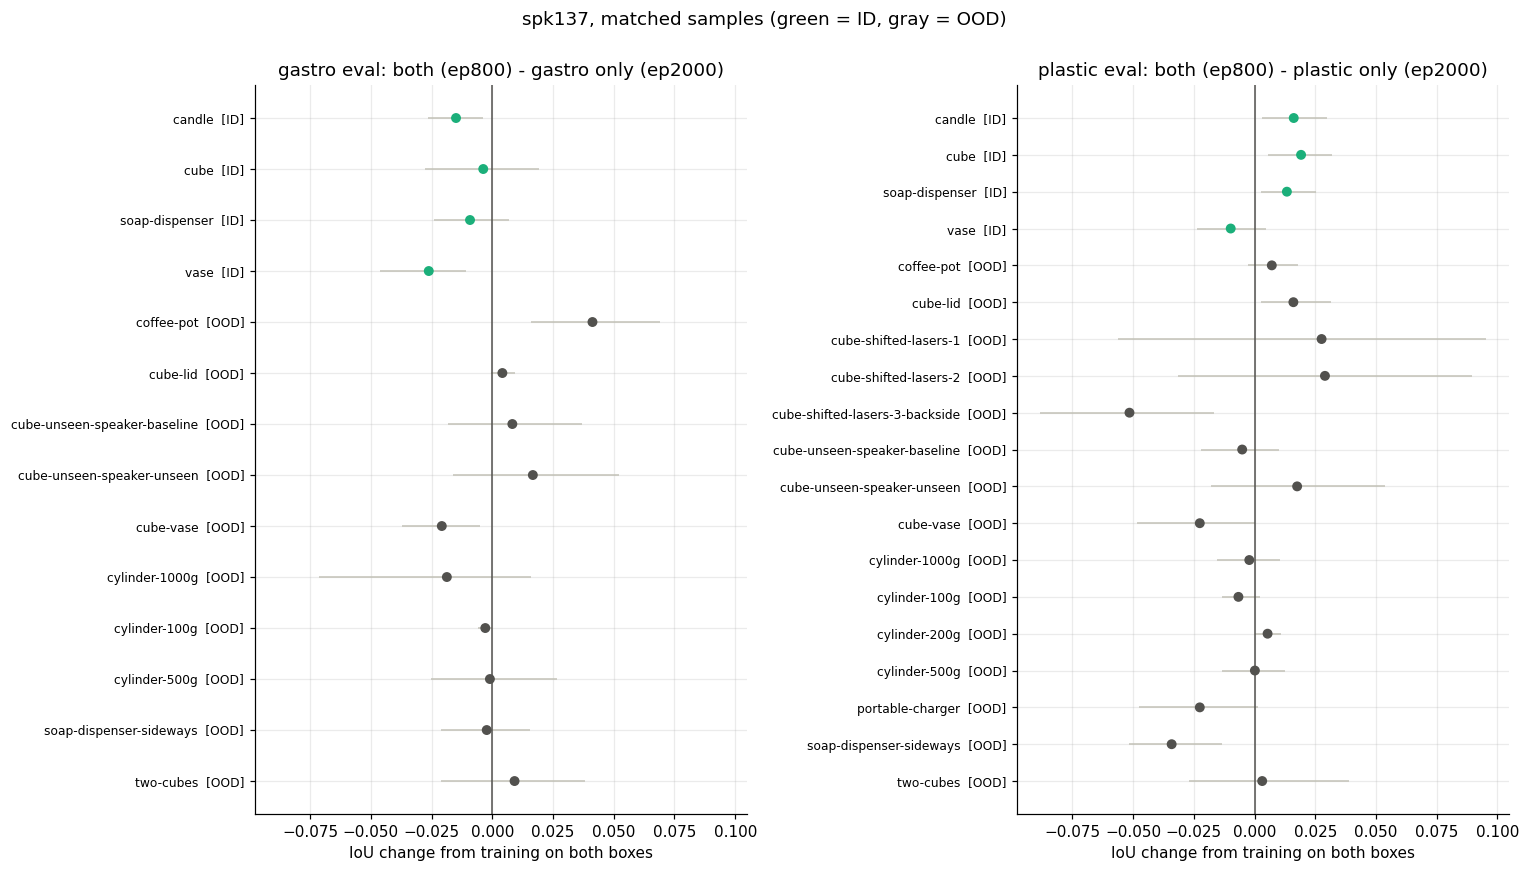

single   both      d
box     kind                      
gastro  ID     0.587  0.574 -0.013
        OOD    0.242  0.245  0.003
plastic ID     0.721  0.730  0.010
        OOD    0.354  0.351 -0.003

In [11]:
delta_plot("spk137", "iou", "IoU change from training on both boxes")
by_kind("spk137", "iou").round(3)

## 4.3 Learning curves
Mean IoU over ID splits (solid) and OOD splits (dashed), against training samples processed. The comparison point is where the single-box run ends.

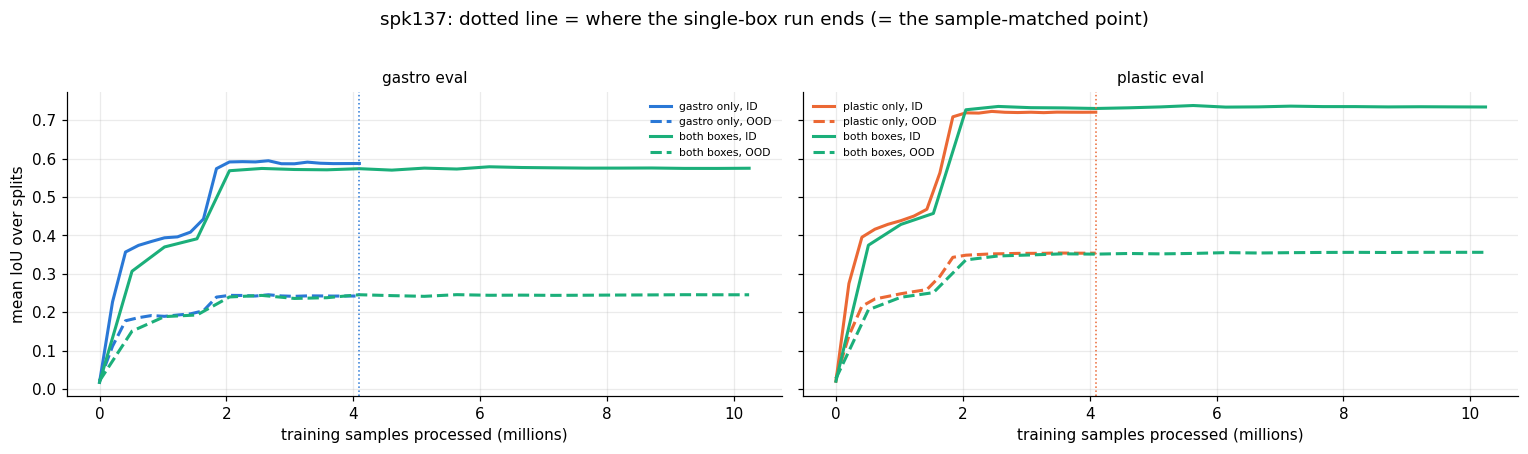

In [12]:
curves("spk137")

## 4.4 Confidence
`fuzz` is the share of painted pixels the model is unsure about; `peak` is its highest pixel probability. The reliability diagram checks whether that confidence is earned.

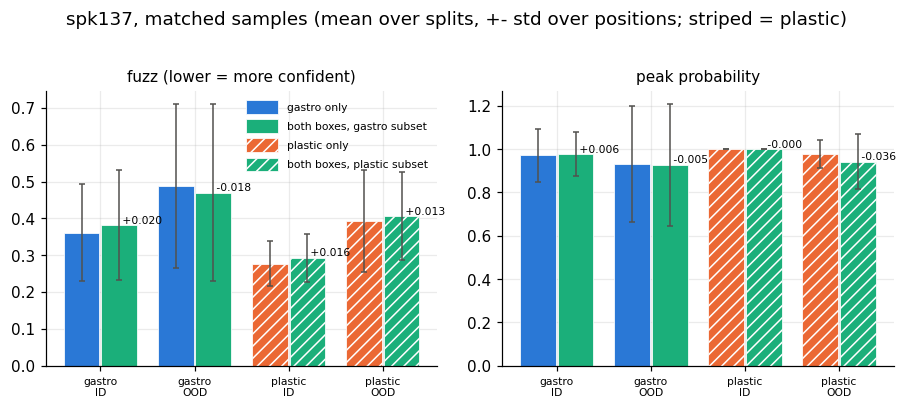

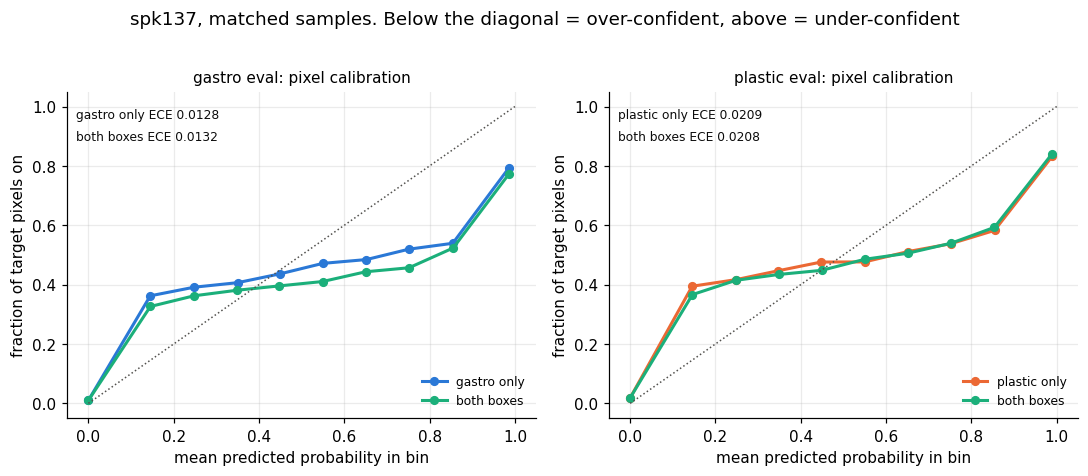

,box,model,ece,over_conf,share_p_gt_0_9
0,gastro,gastro only,0.0128,0.1927,0.6470
1,gastro,both boxes,0.0132,0.2128,0.6390
2,plastic,plastic only,0.0209,0.1574,0.7015
3,plastic,both boxes,0.0208,0.1493,0.6854


In [13]:
kind_bars("spk137", [("fuzz", "fuzz (lower = more confident)"), ("peak", "peak probability")])
reliability("spk137")
ece_table("spk137")

## 4.5 Edges
`contour` is the boundary F-score (higher is better). `band` is how many cells wide the blurry rim is (lower is crisper).

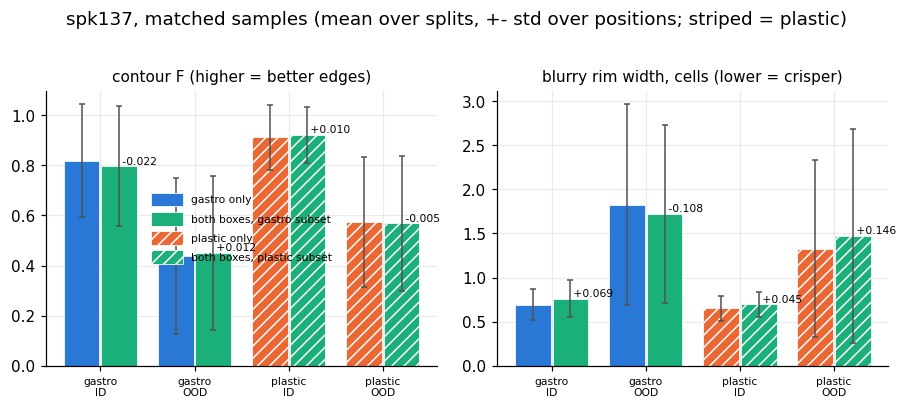

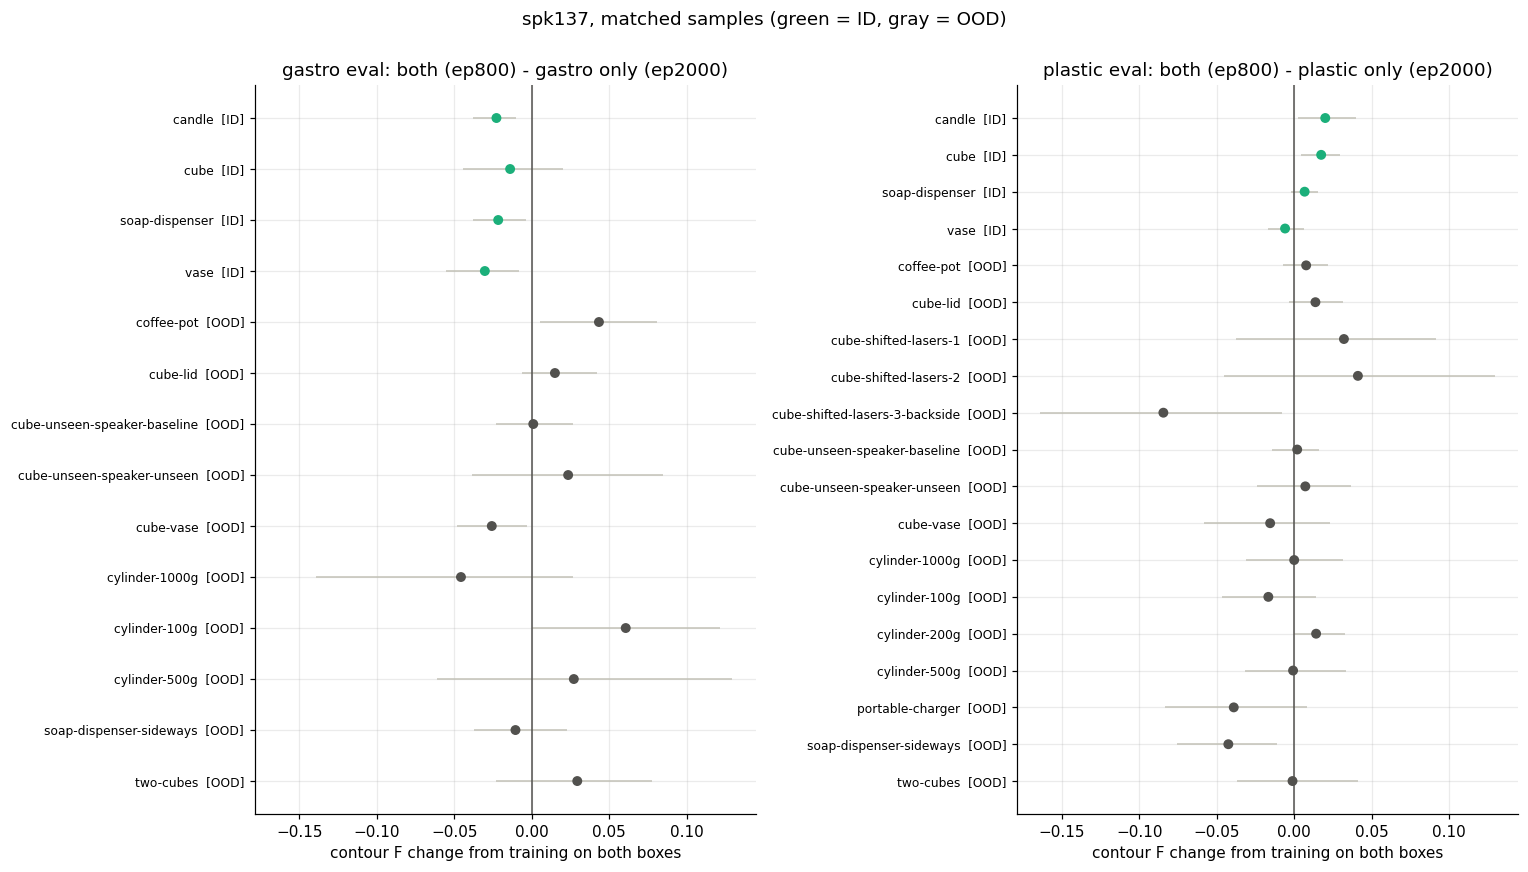

In [14]:
kind_bars("spk137", [("contour", "contour F (higher = better edges)"), ("band", "blurry rim width, cells (lower = crisper)")])
delta_plot("spk137", "contour", "contour F change from training on both boxes")

## 4.6 Painting too little or too much (one number per object)
`paint` < 0 means too little, > 0 too much. The table gives it per split for the single-box model and for `both`.

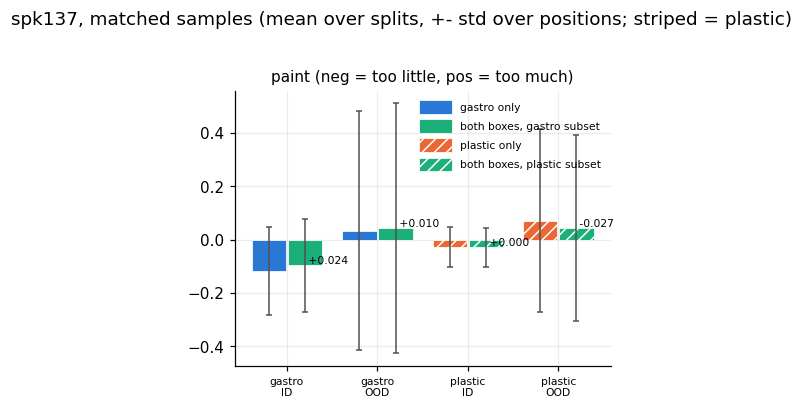

both         single        
box                                 gastro plastic gastro plastic
kind split                                                       
ID   candle                         -0.048  -0.048 -0.055  -0.055
     cube                           -0.188   0.042 -0.248   0.042
     soap-dispenser                 -0.051  -0.049 -0.076  -0.051
     vase                           -0.096  -0.058 -0.098  -0.049
OOD  coffee-pot                     -0.090  -0.186 -0.077  -0.206
     cube-lid                       -0.173  -0.329 -0.114  -0.285
     cube-shifted-lasers-1             NaN   0.108    NaN   0.096
     cube-shifted-lasers-2             NaN  -0.181    NaN  -0.283
     cube-shifted-lasers-3-backside    NaN  -0.545    NaN  -0.035
     cube-unseen-speaker-baseline   -0.157   0.034 -0.186   0.048
     cube-unseen-speaker-unseen     -0.504   0.009 -0.489   0.003
     cube-vase                      -0.380  -0.445 -0.347  -0.411
     cylinder-1000g                  0.554   0.461  0.534   0.461
     cylinder-100g                   0.820   0.842  0.790   0.826
     cylinder-200g                     NaN   0.750    NaN   0.744
     cylinder-500g                   0.500   0.602  0.436   0.602
     portable-charger                  NaN  -0.270    NaN  -0.263
     soap-dispenser-sideways         0.103  -0.082  0.093  -0.068
     two-cubes                      -0.242  -0.121 -0.307  -0.179

In [15]:
kind_bars("spk137", [("paint", "paint (neg = too little, pos = too much)")])
paint_table("spk137")

## 4.7 Counting and localization

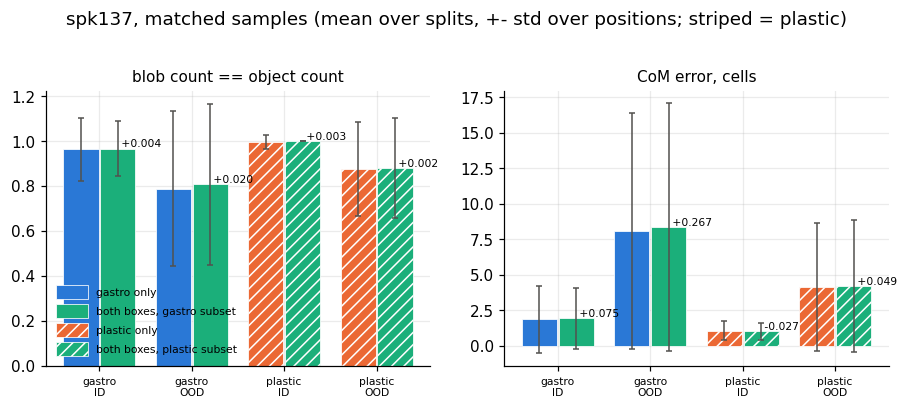

n_pred                    0     1     2    3+
box     model  n_true                        
gastro  both   1       0.04  0.93  0.03  0.00
               2       0.04  0.21  0.68  0.07
        single 1       0.04  0.93  0.03  0.00
               2       0.03  0.21  0.69  0.07
plastic both   1       0.02  0.97  0.01  0.00
               2       0.00  0.31  0.64  0.05
        single 1       0.01  0.97  0.02  0.01
               2       0.01  0.24  0.73  0.01

In [16]:
kind_bars("spk137", [("count_ok", "blob count == object count"), ("com_px", "CoM error, cells")])
c = matched("spk137").assign(n_pred=lambda d: d.n_pred.clip(upper=3))
pd.crosstab([c.box, c.model, c.n_true], c.n_pred, normalize="index").round(2).rename(columns={3: "3+"})

## 4.8 Which objects gain

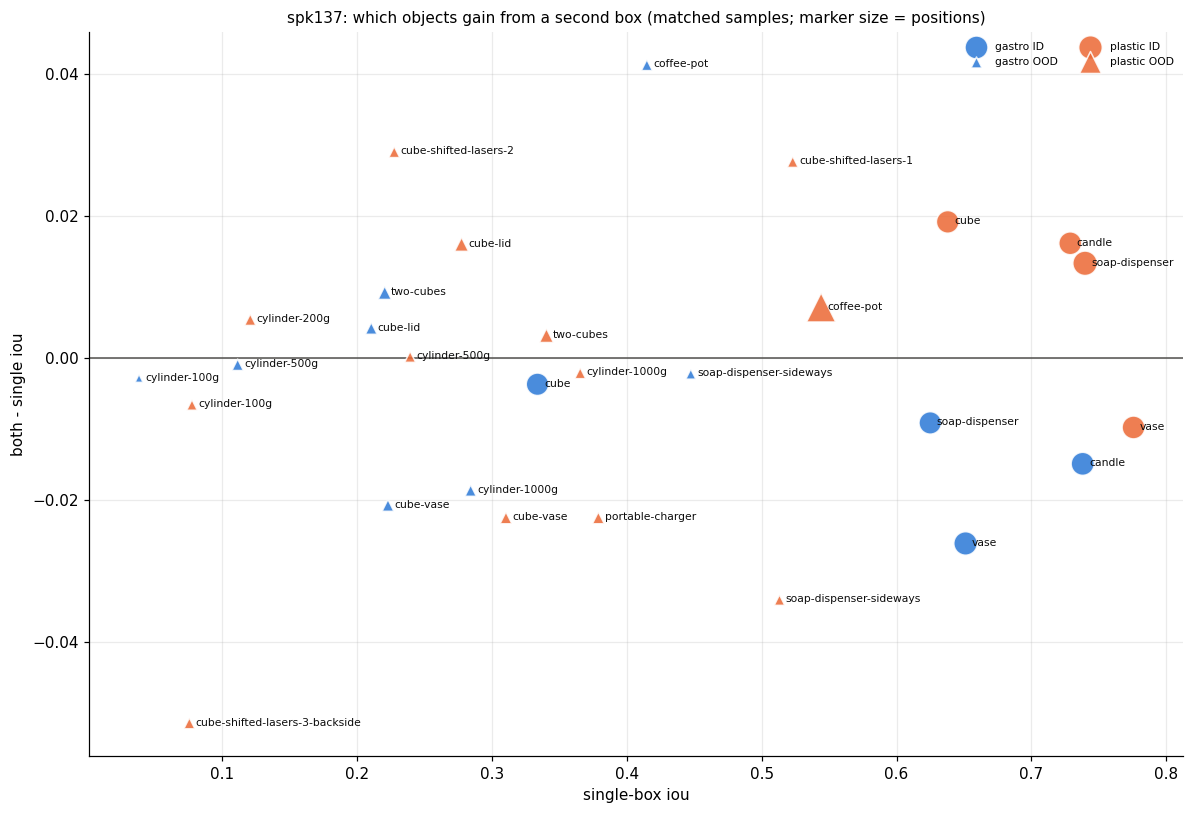

In [17]:
object_gain("spk137")

The same splits as a direct comparison: single-box IoU against `both` IoU. Points above the dotted diagonal are splits where the second box helped. Drawn for all splits, then for each object group (in distribution, two objects, new objects), each zoomed to its own range.

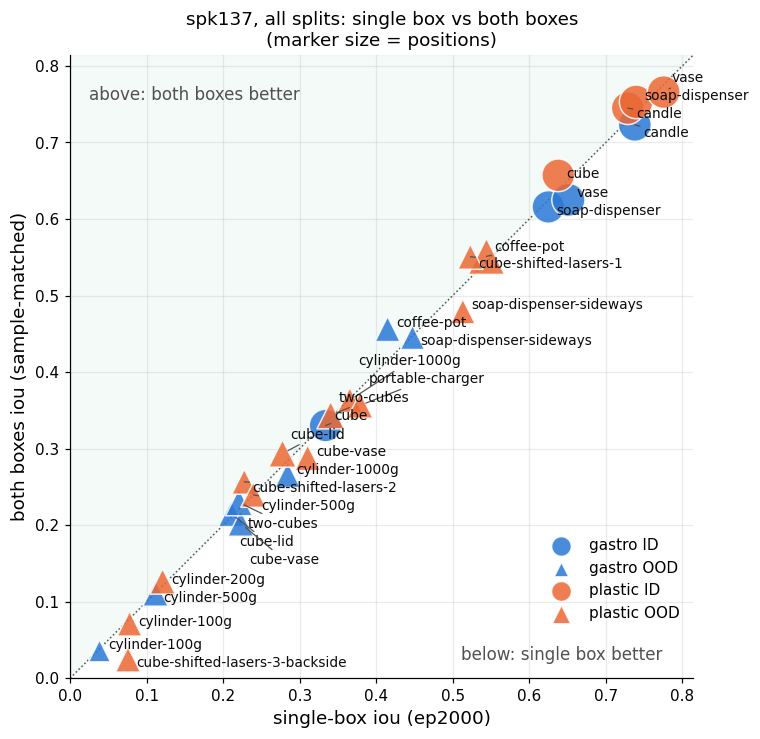

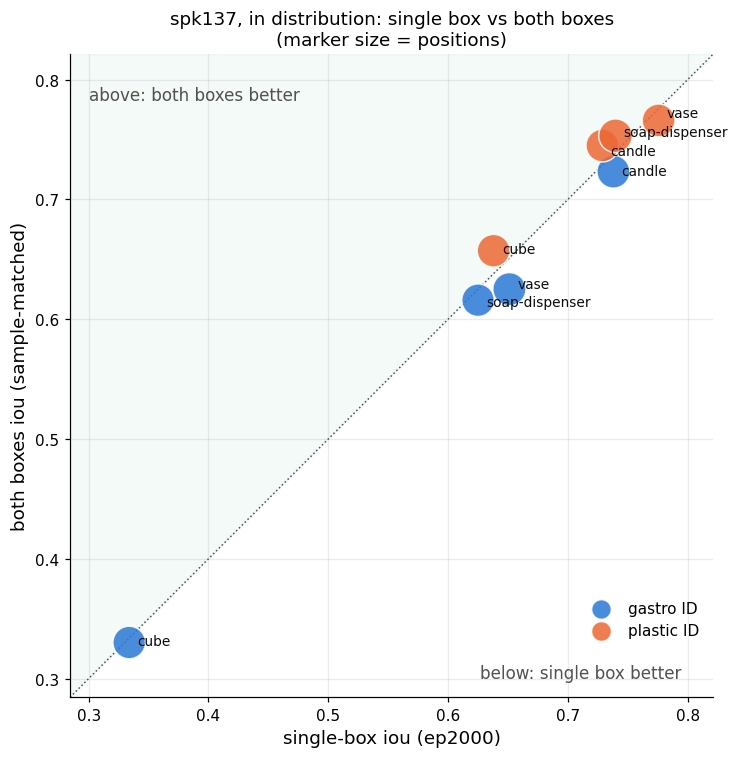

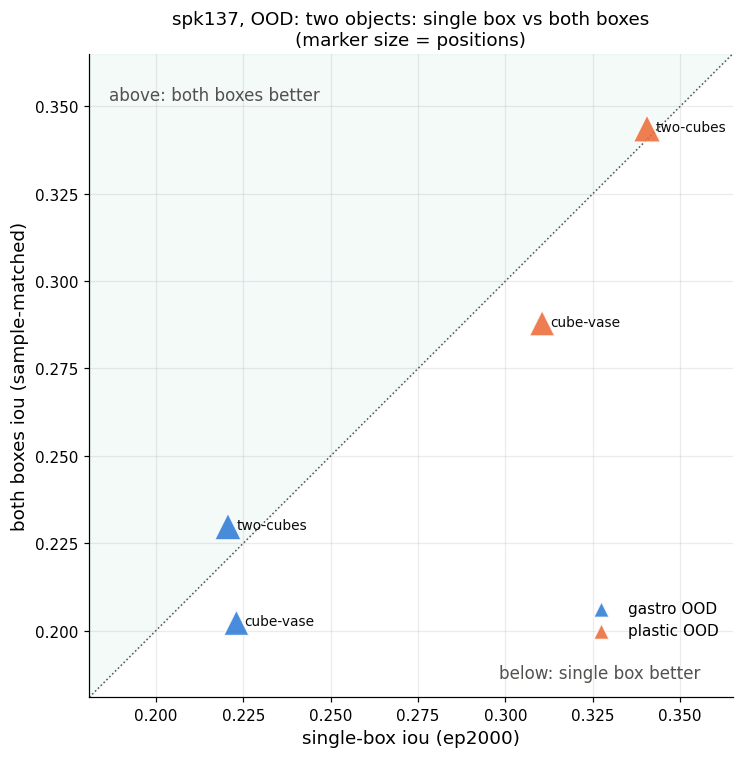

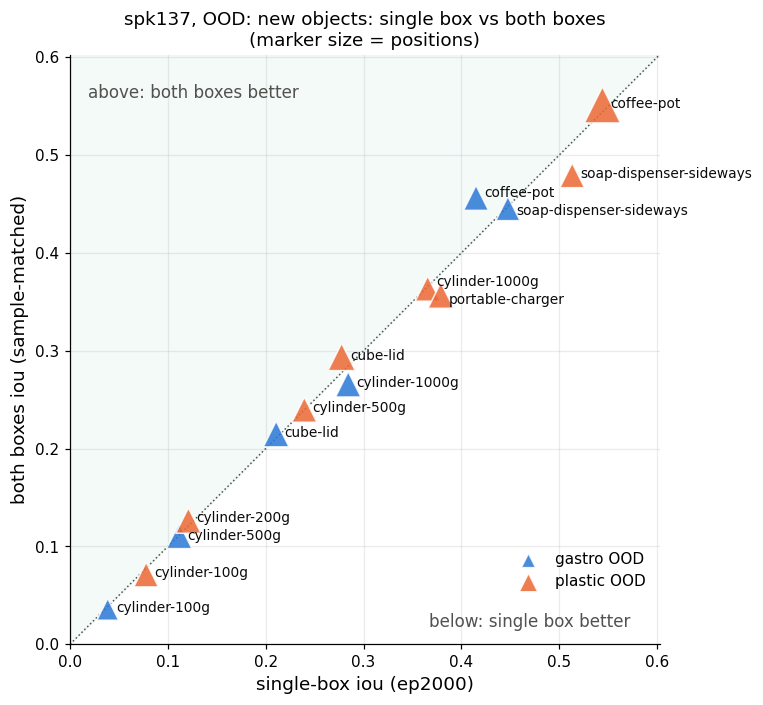

,box,split,kind,single,both,d,lo,hi,n_pos
20,plastic,cube-shifted-lasers-3-backside,OOD,0.076,0.024,-0.051,-0.089,-0.020,8
30,plastic,soap-dispenser-sideways,OOD,0.513,0.479,-0.034,-0.051,-0.016,7
13,gastro,vase,ID,0.651,0.625,-0.026,-0.046,-0.009,54
23,plastic,cube-vase,OOD,0.310,0.288,-0.023,-0.049,-0.001,10
28,plastic,portable-charger,OOD,0.379,0.356,-0.023,-0.045,0.002,10
6,gastro,cube-vase,OOD,0.223,0.202,-0.021,-0.035,-0.007,10
7,gastro,cylinder-1000g,OOD,0.284,0.266,-0.019,-0.074,0.013,9
0,gastro,candle,ID,0.738,0.723,-0.015,-0.027,-0.004,52
32,plastic,vase,ID,0.776,0.766,-0.010,-0.024,0.003,51
10,gastro,soap-dispenser,ID,0.625,0.616,-0.009,-0.026,0.006,49


In [18]:
object_scatter("spk137")
delta_table("spk137", "iou").sort_values("d").round(3)

## 4.9 Five takeaways (spk137)

All numbers compare at equal training samples processed: single-box at ep2000 vs `both` at ep800, both 4.1M samples. ID = cube, candle, vase and soap-dispenser; OOD = everything else.

**1. A second box costs gastro a little and gives plastic a little.** Averaged per split, `both` minus single is **-0.013 on gastro ID** and **+0.010 on plastic ID**. OOD moves by only +0.003 and -0.003. The plastic gains are consistent: cube +0.019, candle +0.016 and soap-dispenser +0.013, all with CIs above 0. The gastro losses are vase -0.026 and candle -0.015 (both CIs below 0), with soap-dispenser -0.009 and cube -0.004.

**2. OOD is a wash overall, with a few clear losers on plastic.** Most OOD splits stay within +-0.02. The losers are plastic soap-dispenser-sideways (-0.034) and the backside-laser cube (-0.051). The portable charger (-0.023) and cube-vase on both boxes (-0.02) are borderline. Small gains: plastic cube-lid +0.016, plus the unseen speaker on both boxes (+0.017/+0.018, wide CIs).

**3. Not more confident at equal samples.** On ID, `both` has a slightly higher share of unsure pixels (gastro 0.38 vs 0.36, plastic 0.29 vs 0.28). It also puts fewer pixels above 0.9 (gastro 64% vs 65%, plastic 69% vs 70%). Calibration error is unchanged (0.013 vs 0.013, 0.021 vs 0.021). On OOD its highest pixel is lower, i.e. it hedges more on unfamiliar inputs (plastic 0.94 vs 0.98). This fits `both` being mid-schedule, not yet annealed.

**4. Edges follow IoU, and painting is better balanced.** Boundary F is lower on gastro ID (0.80 vs 0.82) and higher on plastic ID (0.92 vs 0.91). The blurry rim is a bit wider on ID for both boxes (0.70-0.76 vs 0.65-0.69 cells). `both` under-paints seen objects less (gastro -0.10 vs -0.12) and halves the under-paint on gastro cube (-0.19 vs -0.25). It also over-paints plastic OOD objects less (+0.04 vs +0.07). The backside-laser cube is the exception: badly under-painted (-0.55 vs -0.04).

**5. Two-object scenes on plastic get merged.** On plastic, `both` turns a two-object scene into one blob 31% of the time vs 24%, so exact counts drop from 0.73 to 0.64. Gastro counting is unchanged (0.68 vs 0.69).

# 5 Setting 2: all the data (allspk)

Every model here is scored at **ep2000**, the end of its run: matched on epochs, not on samples (see the top of the notebook).

## 5.1 Each box: its own model vs its subset of `both`
The `both` model's score splits into a gastro part and a plastic part. Each part is compared with the model trained on that box alone, first as one headline number per box, then split by split. Each split-level plot is drawn for all splits, then for three groups: **in distribution** (cube, candle, vase, soap-dispenser), **OOD: two objects** (two-cubes, cube-vase) and **OOD: new objects** (objects never trained on).

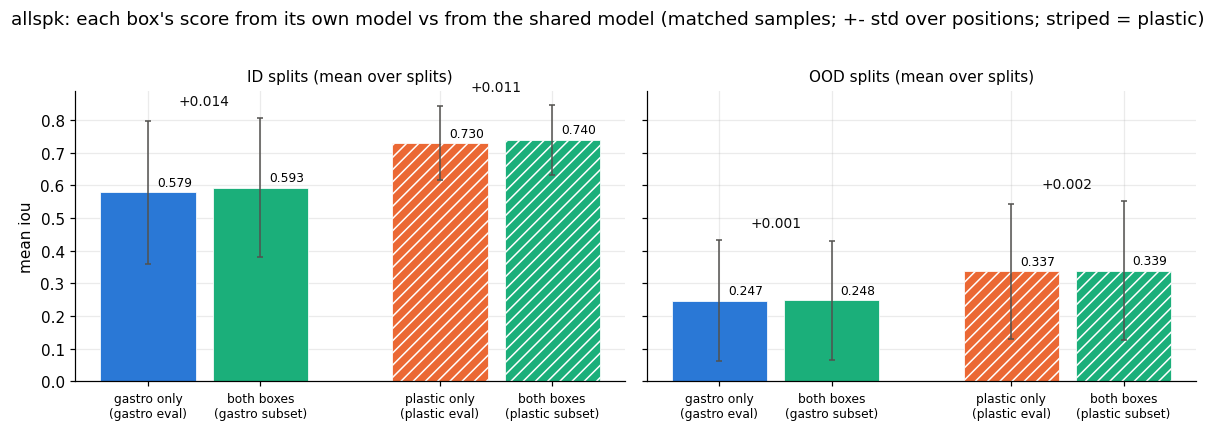

In [19]:
four_bars("allspk")

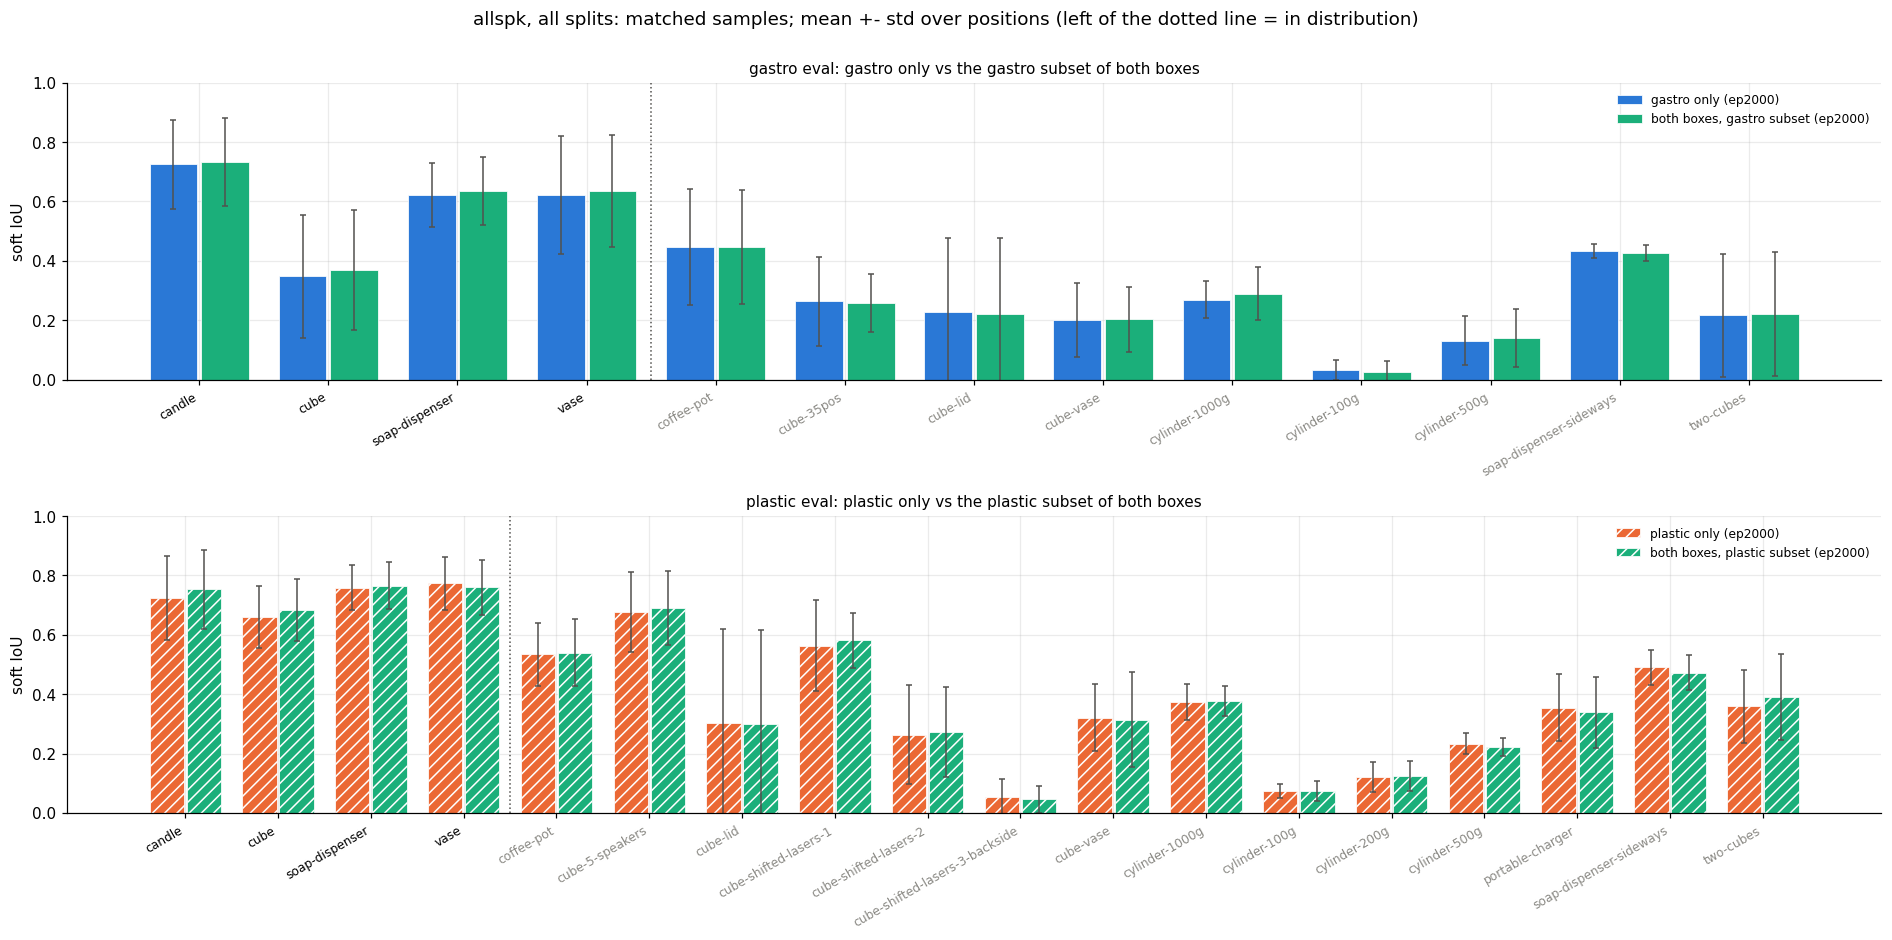

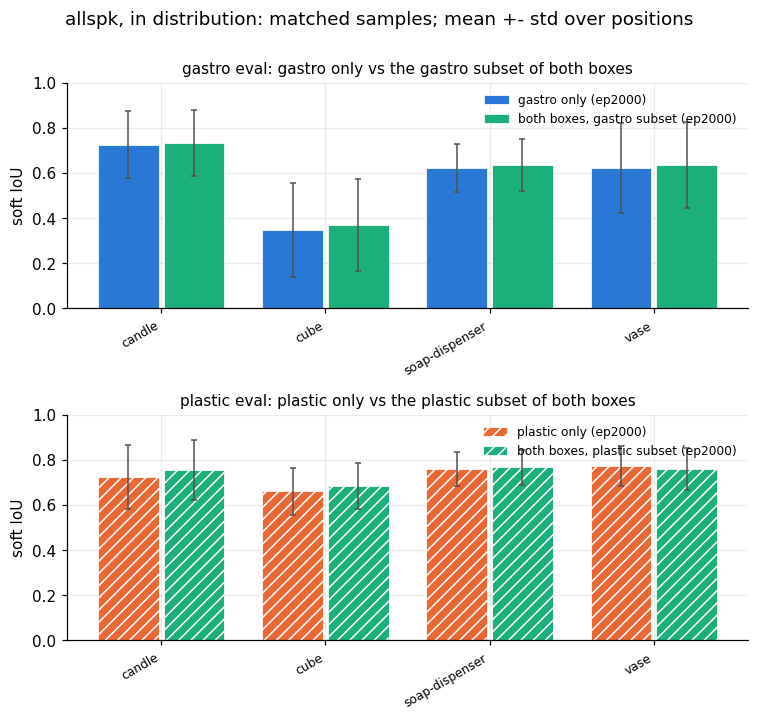

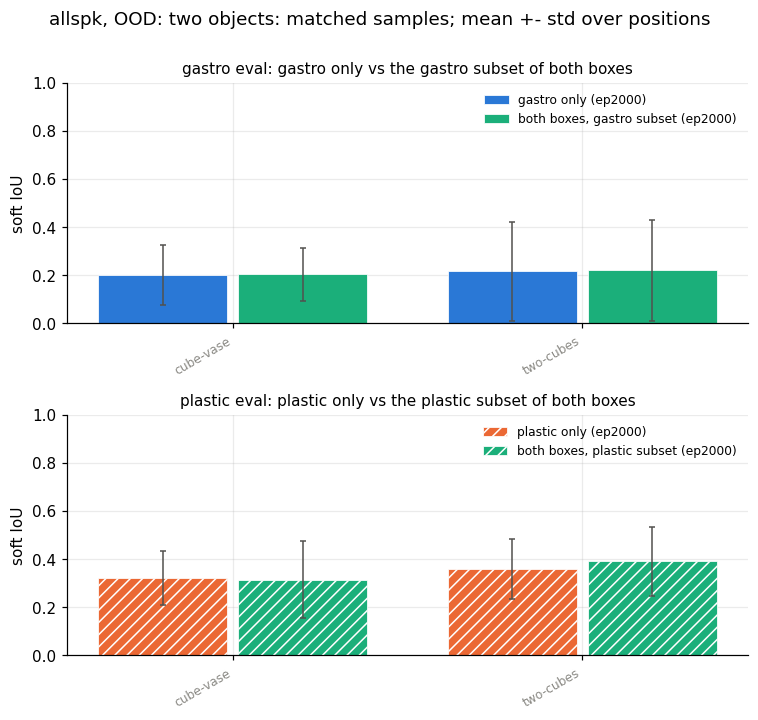

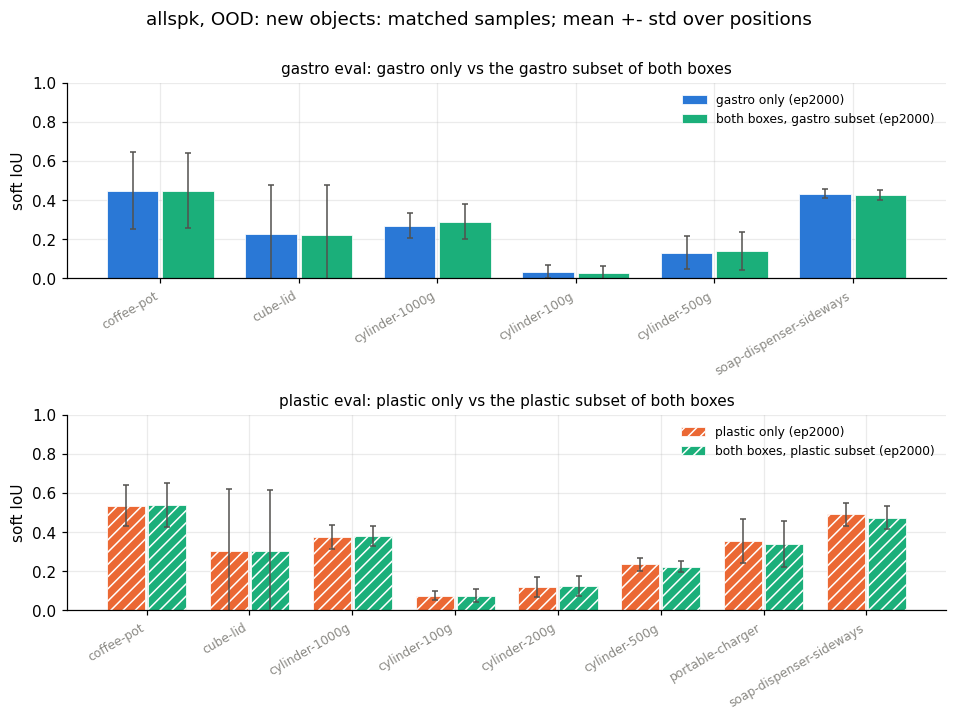

In [20]:
per_box_plot("allspk")

Same as above, but for the objects both boxes have, with all four bars side by side.

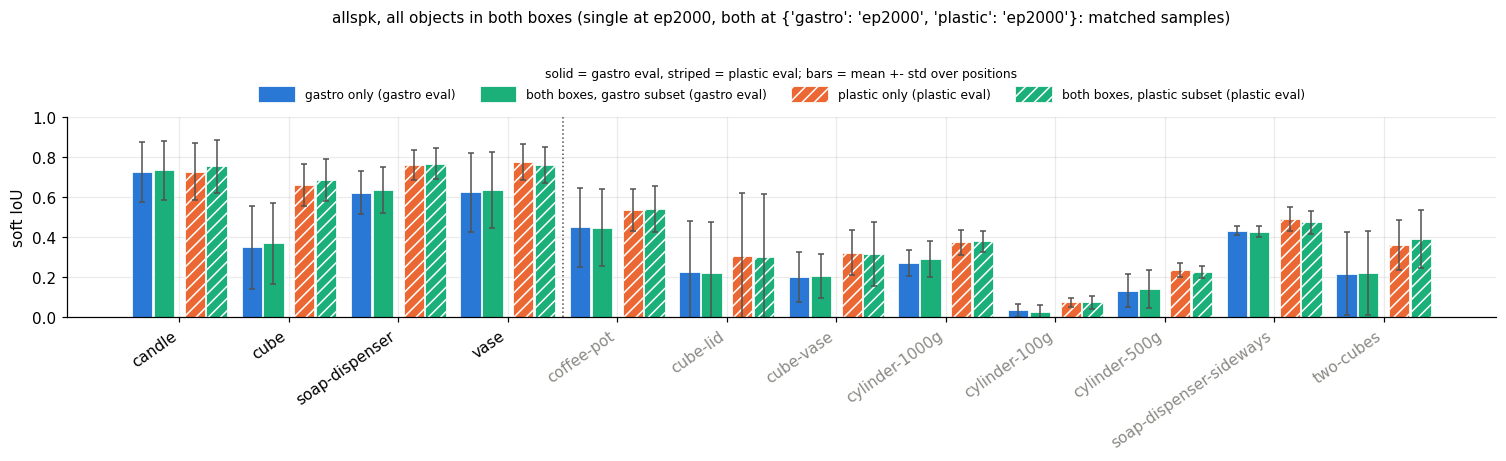

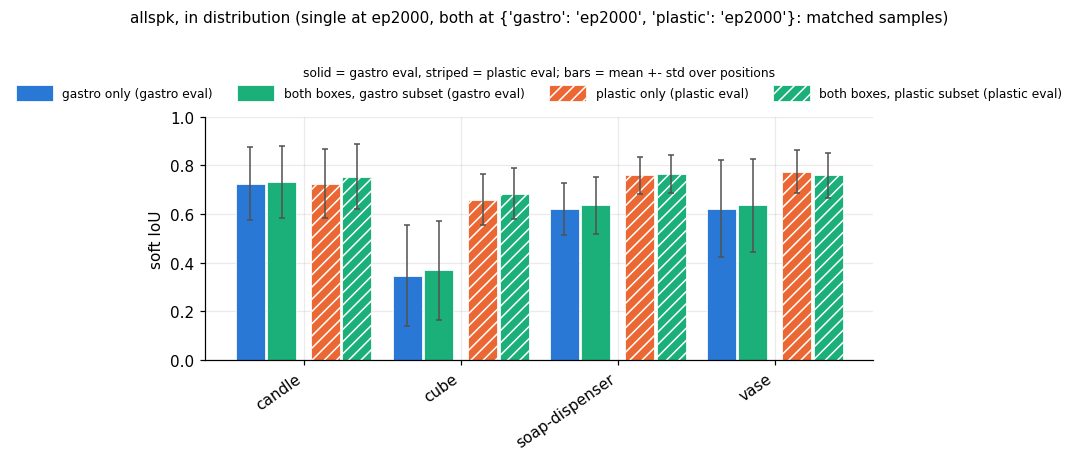

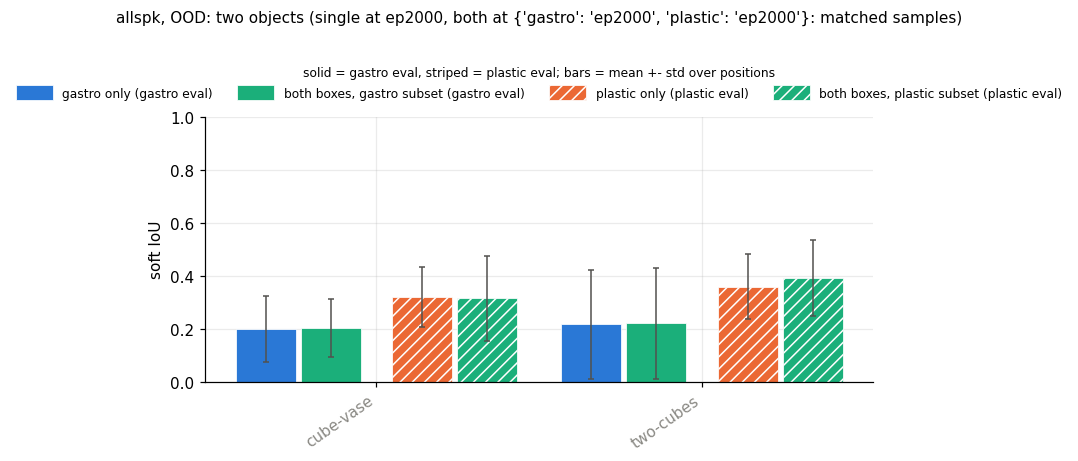

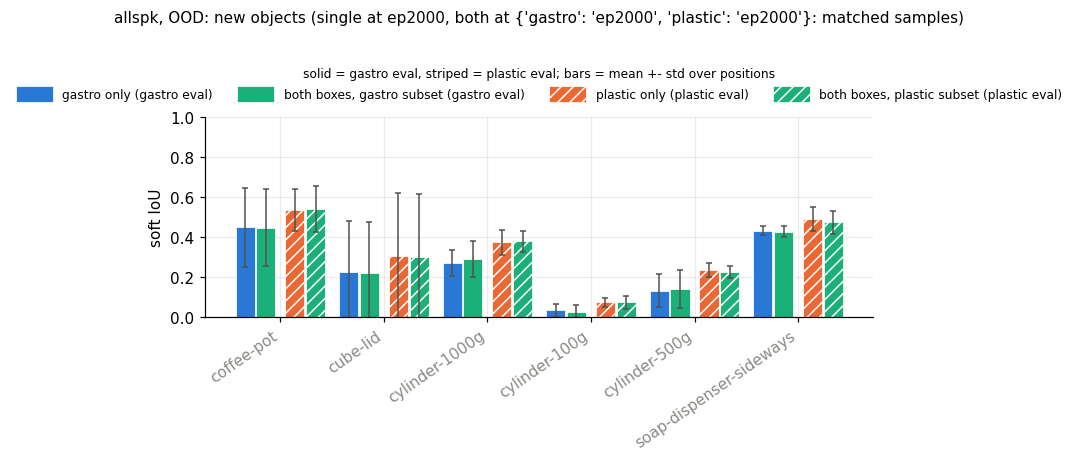

In [21]:
combined_plot("allspk")

## 5.2 Every split, as a difference
Each dot is `both - single` for one split, with a 95% CI over positions.

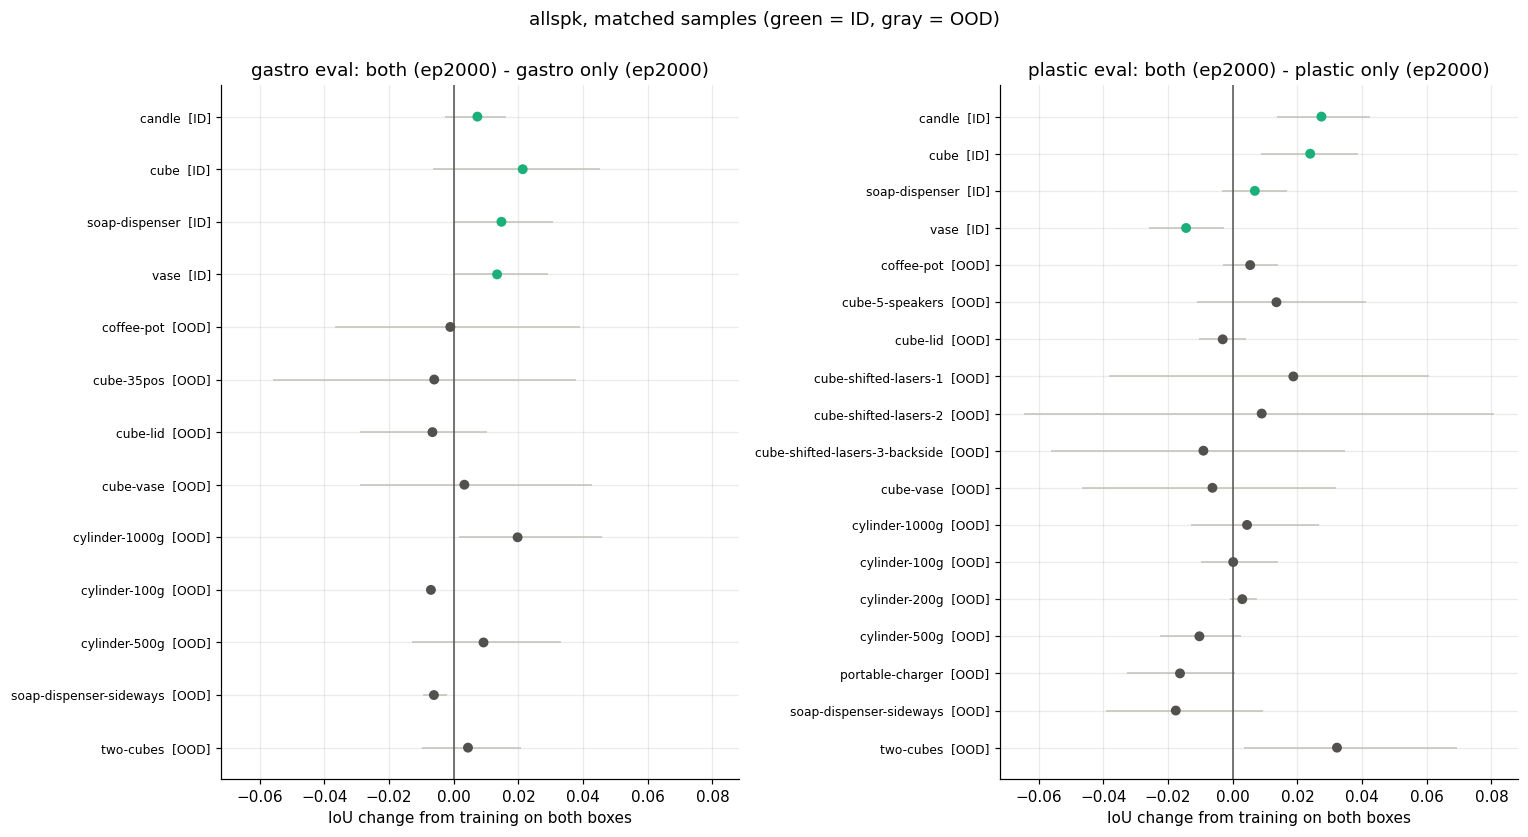

single   both      d
box     kind                      
gastro  ID     0.579  0.593  0.014
        OOD    0.247  0.248  0.001
plastic ID     0.730  0.741  0.011
        OOD    0.337  0.339  0.002

In [22]:
delta_plot("allspk", "iou", "IoU change from training on both boxes")
by_kind("allspk", "iou").round(3)

## 5.3 Learning curves
Mean IoU over ID splits (solid) and OOD splits (dashed), against training samples processed. The comparison point is where the single-box run ends.

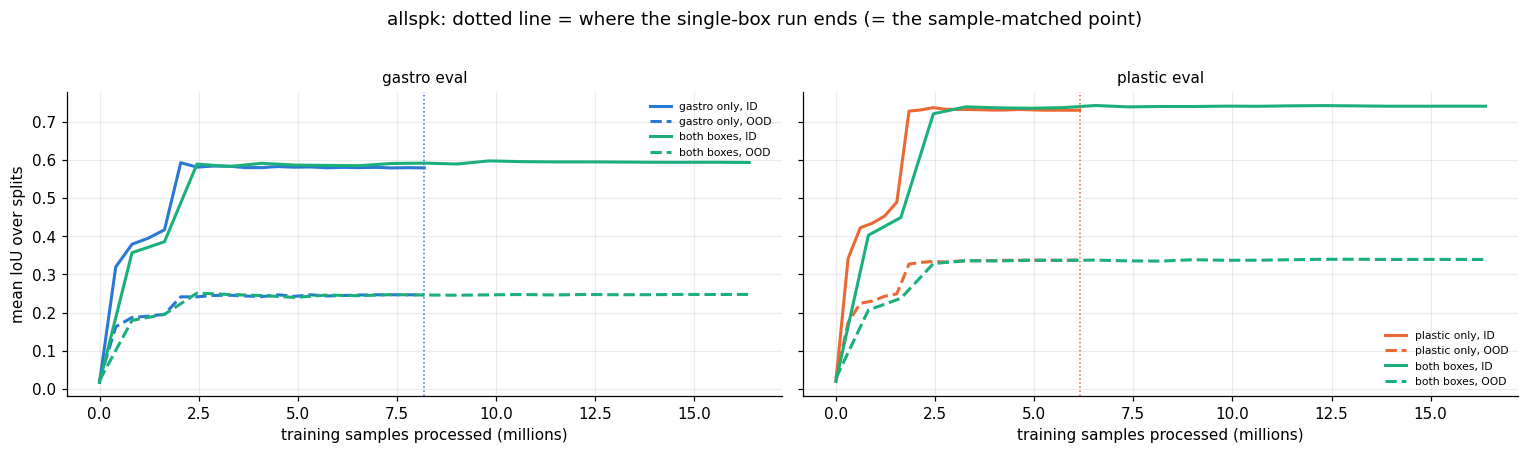

In [23]:
curves("allspk")

## 5.4 Confidence
`fuzz` is the share of painted pixels the model is unsure about; `peak` is its highest pixel probability. The reliability diagram checks whether that confidence is earned.

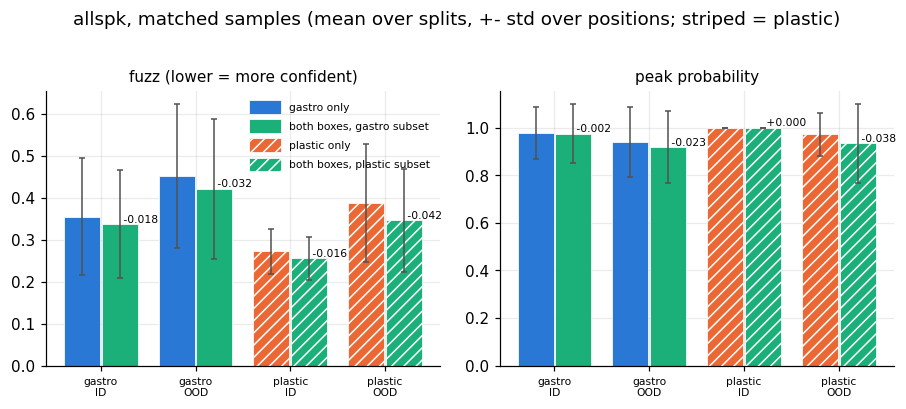

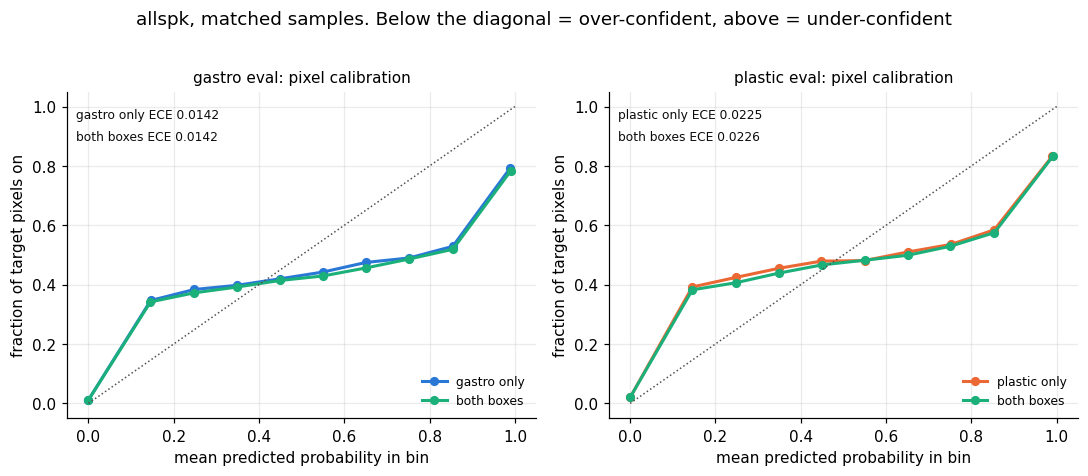

,box,model,ece,over_conf,share_p_gt_0_9
0,gastro,gastro only,0.0142,0.1962,0.6739
1,gastro,both boxes,0.0142,0.2068,0.6894
2,plastic,plastic only,0.0225,0.1569,0.7021
3,plastic,both boxes,0.0226,0.1579,0.7280


In [24]:
kind_bars("allspk", [("fuzz", "fuzz (lower = more confident)"), ("peak", "peak probability")])
reliability("allspk")
ece_table("allspk")

## 5.5 Edges
`contour` is the boundary F-score (higher is better). `band` is how many cells wide the blurry rim is (lower is crisper).

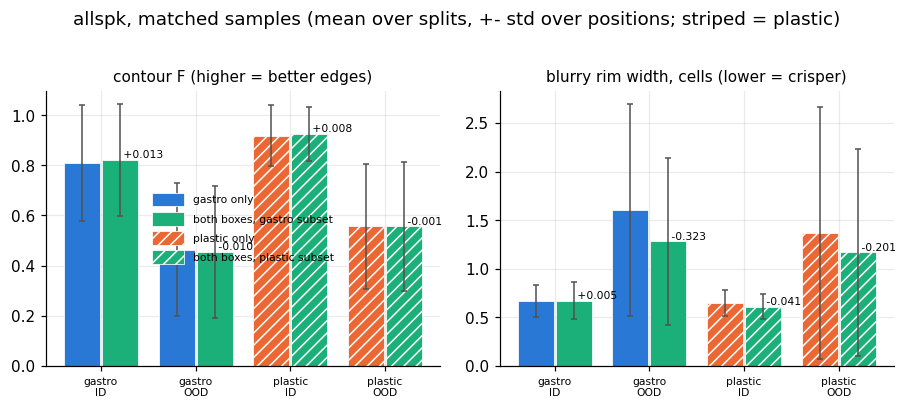

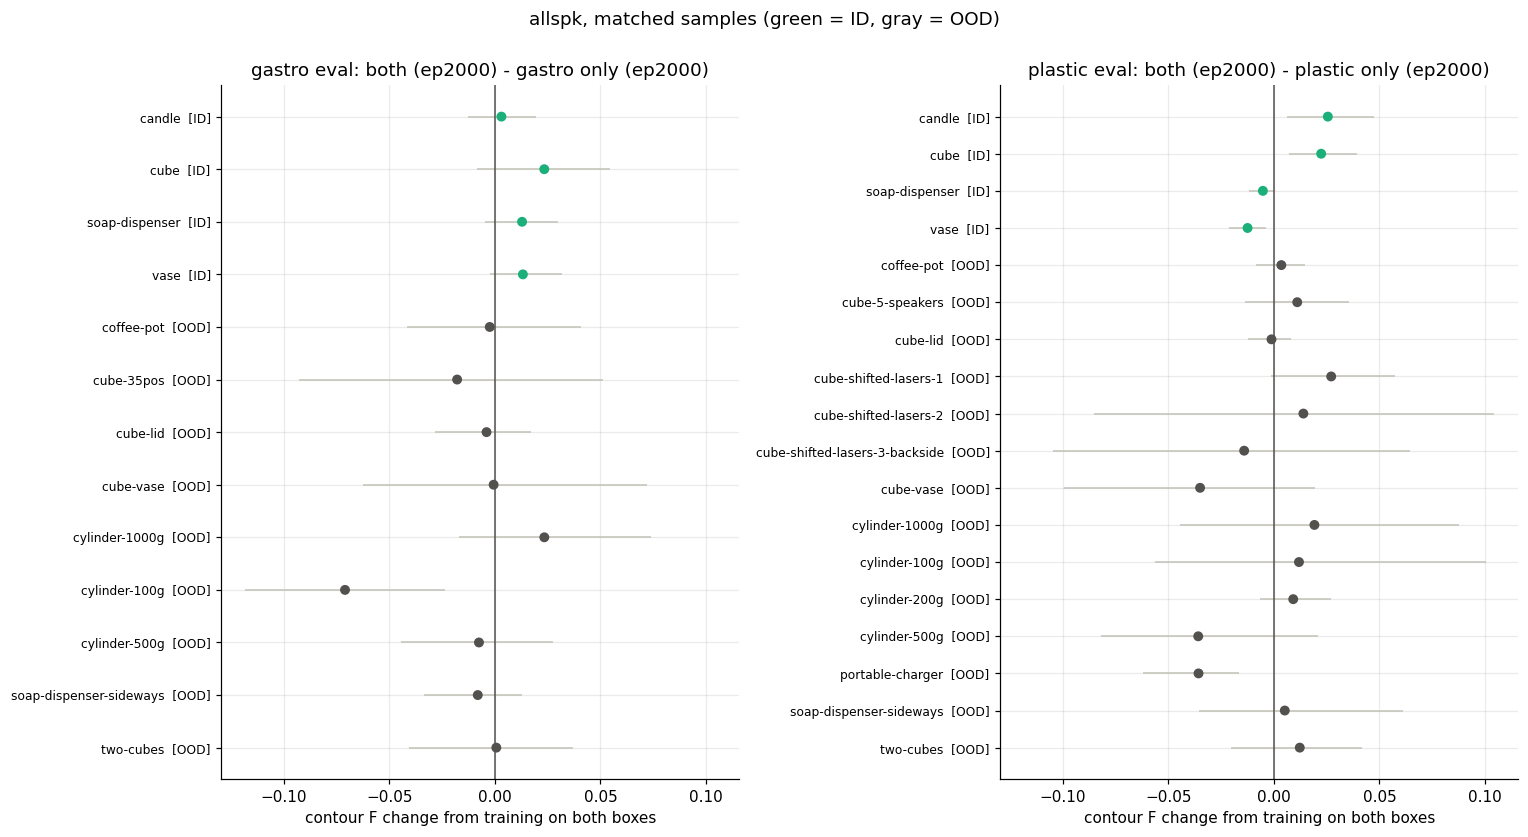

In [25]:
kind_bars("allspk", [("contour", "contour F (higher = better edges)"), ("band", "blurry rim width, cells (lower = crisper)")])
delta_plot("allspk", "contour", "contour F change from training on both boxes")

## 5.6 Painting too little or too much (one number per object)
`paint` < 0 means too little, > 0 too much. The table gives it per split for the single-box model and for `both`.

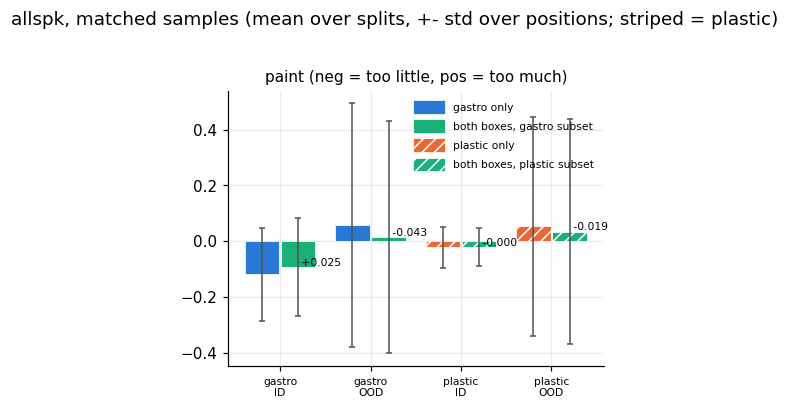

both         single        
box                                 gastro plastic gastro plastic
kind split                                                       
ID   candle                         -0.046  -0.048 -0.061  -0.061
     cube                           -0.175   0.046 -0.233   0.056
     soap-dispenser                 -0.053  -0.036 -0.068  -0.037
     vase                           -0.101  -0.053 -0.116  -0.049
OOD  coffee-pot                     -0.080  -0.197 -0.085  -0.202
     cube-35pos                     -0.133     NaN -0.142     NaN
     cube-5-speakers                   NaN   0.029    NaN   0.029
     cube-lid                       -0.129  -0.382 -0.104  -0.295
     cube-shifted-lasers-1             NaN   0.052    NaN   0.068
     cube-shifted-lasers-2             NaN  -0.135    NaN  -0.260
     cube-shifted-lasers-3-backside    NaN  -0.667    NaN  -0.386
     cube-vase                      -0.373  -0.374 -0.398  -0.368
     cylinder-1000g                  0.514   0.447  0.510   0.451
     cylinder-100g                  -0.022   0.834  0.472   0.852
     cylinder-200g                     NaN   0.759    NaN   0.759
     cylinder-500g                   0.530   0.615  0.541   0.613
     portable-charger                  NaN  -0.301    NaN  -0.304
     soap-dispenser-sideways         0.066  -0.102  0.053  -0.086
     two-cubes                      -0.249  -0.107 -0.337  -0.135

In [26]:
kind_bars("allspk", [("paint", "paint (neg = too little, pos = too much)")])
paint_table("allspk")

## 5.7 Counting and localization

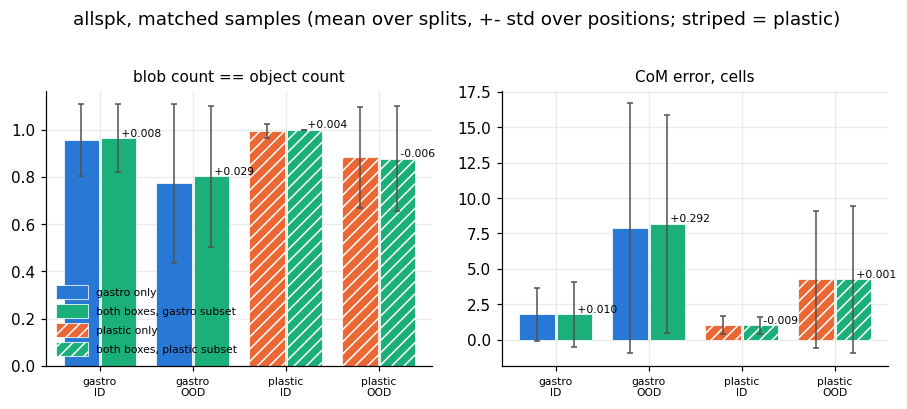

n_pred                    0     1     2    3+
box     model  n_true                        
gastro  both   1       0.03  0.94  0.03  0.00
               2       0.06  0.20  0.68  0.06
        single 1       0.03  0.93  0.04  0.00
               2       0.07  0.26  0.62  0.05
plastic both   1       0.03  0.97  0.01  0.00
               2       0.01  0.27  0.69  0.03
        single 1       0.01  0.97  0.02  0.01
               2       0.00  0.18  0.75  0.07

In [27]:
kind_bars("allspk", [("count_ok", "blob count == object count"), ("com_px", "CoM error, cells")])
c = matched("allspk").assign(n_pred=lambda d: d.n_pred.clip(upper=3))
pd.crosstab([c.box, c.model, c.n_true], c.n_pred, normalize="index").round(2).rename(columns={3: "3+"})

## 5.8 Which objects gain

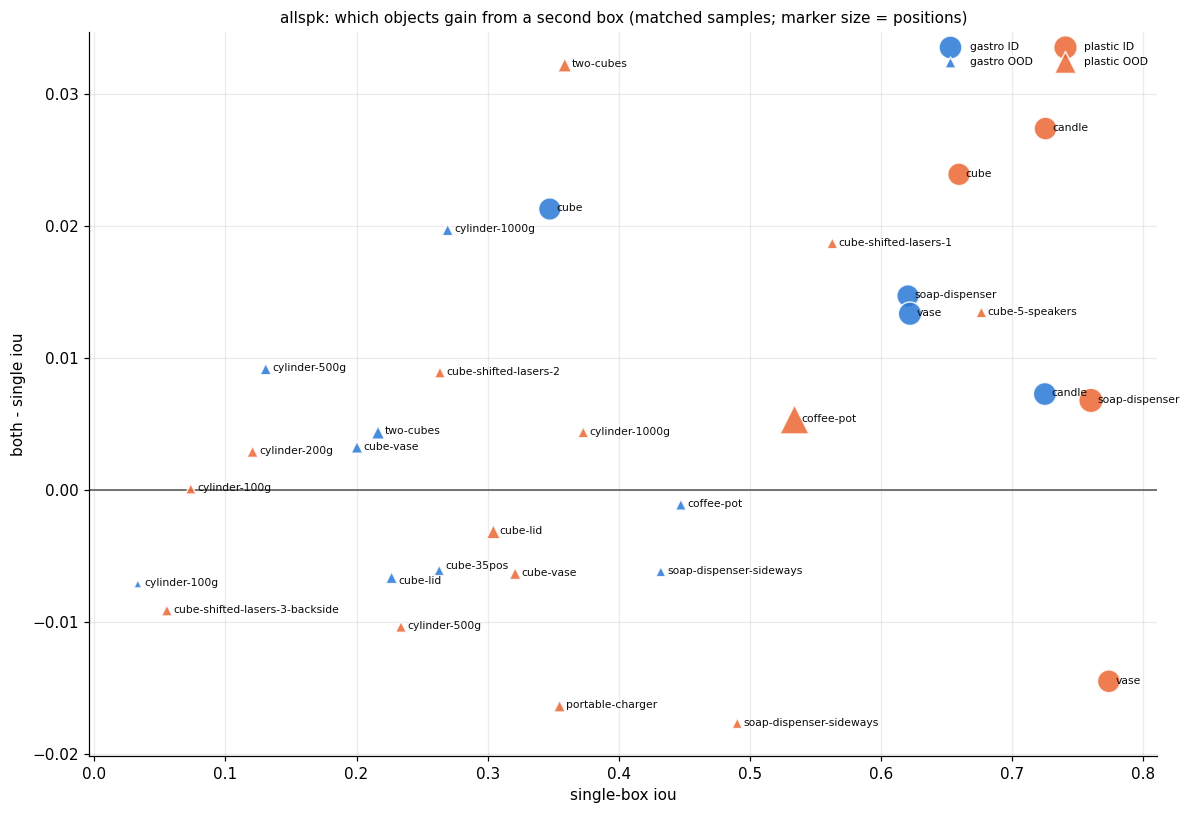

In [28]:
object_gain("allspk")

The same splits as a direct comparison: single-box IoU against `both` IoU. Points above the dotted diagonal are splits where the second box helped. Drawn for all splits, then for each object group (in distribution, two objects, new objects), each zoomed to its own range.

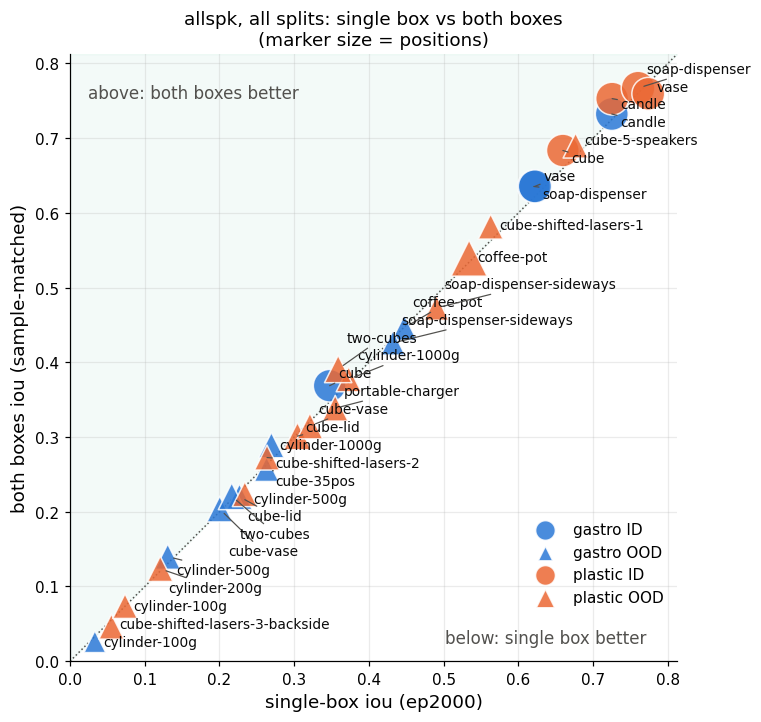

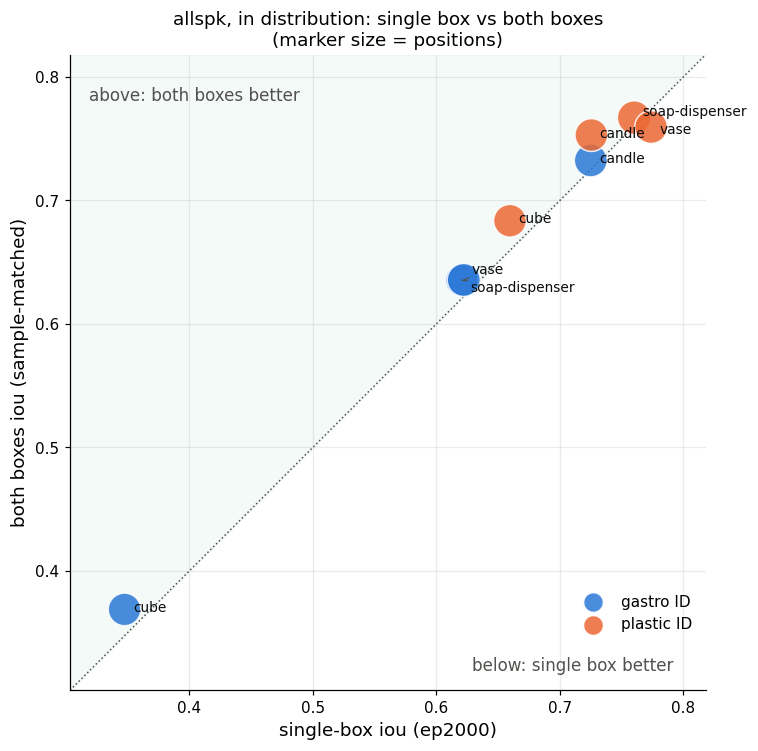

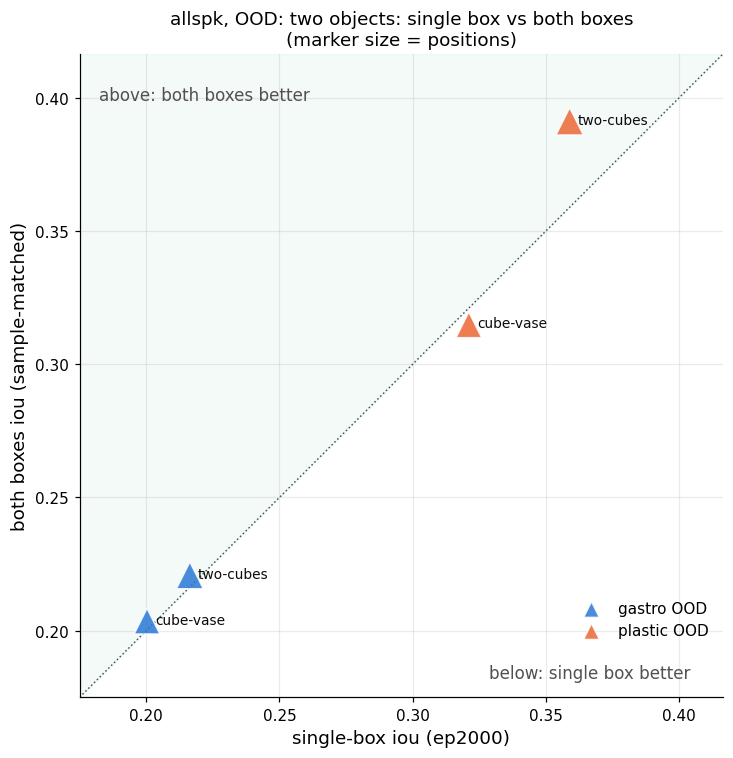

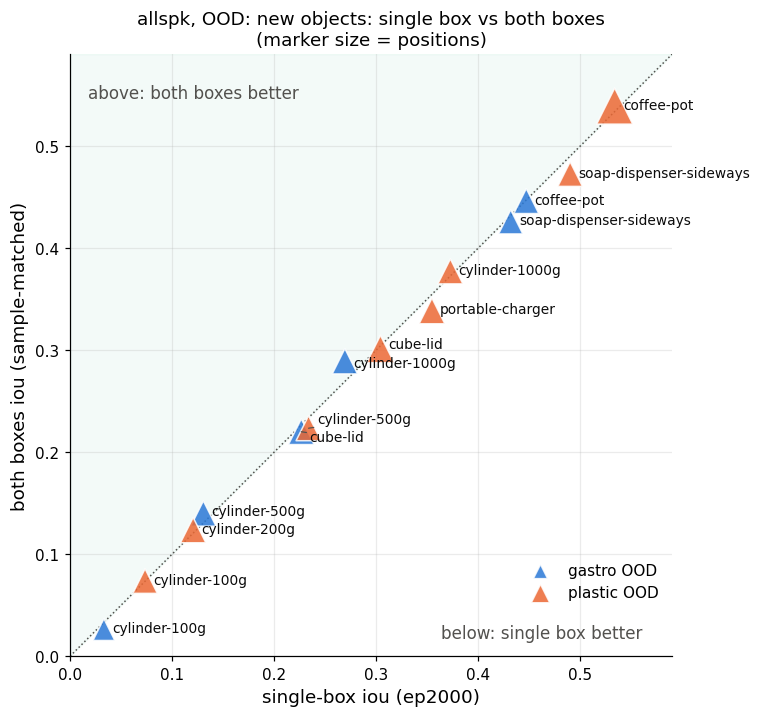

,box,split,kind,single,both,d,lo,hi,n_pos
28,plastic,soap-dispenser-sideways,OOD,0.490,0.473,-0.018,-0.039,0.011,7
26,plastic,portable-charger,OOD,0.355,0.339,-0.016,-0.031,0.001,10
30,plastic,vase,ID,0.774,0.759,-0.014,-0.026,-0.003,51
25,plastic,cylinder-500g,OOD,0.234,0.224,-0.010,-0.022,0.004,8
20,plastic,cube-shifted-lasers-3-backside,OOD,0.055,0.046,-0.009,-0.056,0.042,8
7,gastro,cylinder-100g,OOD,0.033,0.026,-0.007,-0.009,-0.006,2
4,gastro,cube-lid,OOD,0.227,0.220,-0.007,-0.029,0.012,10
21,plastic,cube-vase,OOD,0.321,0.315,-0.006,-0.047,0.030,10
10,gastro,soap-dispenser-sideways,OOD,0.432,0.426,-0.006,-0.011,-0.001,6
3,gastro,cube-35pos,OOD,0.263,0.257,-0.006,-0.058,0.039,7


In [29]:
object_scatter("allspk")
delta_table("allspk", "iou").sort_values("d").round(3)

## 5.9 Five takeaways (allspk)

Every model is at ep2000, the end of its run, so `both` has seen more samples: 16.4M vs 8.2M (gastro) and 6.1M (plastic). These are the full runs side by side, not a compute-matched cost of sharing (section 6 has the sample-matched view). ID = cube, candle, vase and soap-dispenser; OOD = everything else.

**1. A finished `both` run beats each finished single-box run on ID.** `both` minus single is **+0.014 on gastro ID and +0.011 on plastic ID**, and OOD is flat (+0.001 and +0.002). Gastro: soap-dispenser +0.015 and vase +0.013 (CIs above 0), cube +0.021 (CI just crosses 0), candle +0.007. Plastic: candle +0.027 and cube +0.024 lead (CIs above 0), soap-dispenser +0.007, but vase is -0.014 (CI below 0).

**2. OOD gains and losses are small and mixed.** Gainers: plastic two-cubes +0.032, gastro cylinder-1000g +0.020 and plastic cube-shifted-lasers-1 +0.019. Losers: plastic soap-dispenser-sideways -0.018, plastic portable charger -0.016 and plastic cylinder-500g -0.010. The rest are within +-0.01.

**3. `both` is slightly more confident on ID and hedges more on plastic OOD.** The unsure-pixel share is lower for `both` on every kind (gastro ID 0.34 vs 0.35, plastic ID 0.26 vs 0.27, OOD 0.42 vs 0.45 and 0.33 vs 0.36). Calibration error is identical (0.014 vs 0.014, 0.023 vs 0.023). On plastic OOD its highest pixel is lower (0.95 vs 0.98); on gastro OOD it is the same (0.94).

**4. Edges: a narrower blurry rim on OOD, otherwise about the same.** Boundary F is slightly better on ID (gastro 0.82 vs 0.81, plastic 0.93 vs 0.92). The blurry rim is narrower on OOD (gastro 1.07 vs 1.19 cells, plastic 0.82 vs 0.97). Gastro under-paints less on ID (-0.09 vs -0.12), mostly on cube (-0.18 vs -0.23), and on two-cubes (-0.25 vs -0.34).

**5. Counting: better on gastro, worse on plastic.** On two-object scenes, gastro exact counts rise (0.68 vs 0.62) but plastic's fall (0.69 vs 0.75). On plastic, `both` merges two objects into one blob 27% of the time vs 18%. This is the most consistent cost of sharing: it appears in both settings and at both matchings.

# 6 Speaker-Matched vs All Speakers

Each model is at its sample-matched point, in both settings (for allspk this differs from section 5, which uses ep2000), so the extra training speakers are the only change. The eval positions are the same in both settings. Restricting allspk to speakers 1, 3, 7 therefore gives **the identical samples** spk137 is scored on, so the only change is the extra training speakers (gastro gains 2 and 4, plastic gains 4 and 5).

Questions:
- How much do the extra speakers help each arm?
- Does `both` gain more or less from them than a single-box model does?

In [30]:
same = pd.concat([matched(s, SAMPLE_VIEWS).assign(setting=s) for s in SETTINGS], ignore_index=True)
same = same[same.speaker.isin([1, 3, 7])]
k2 = ["box", "split", "position_id", "speaker"]
common = same[same.setting == "spk137"][k2].merge(same[same.setting == "allspk"][k2]).drop_duplicates()
same = same.merge(common, on=k2)
tab = same.groupby(["box", "kind", "split", "model", "setting"]).iou.mean().unstack(["model", "setting"])
kt = tab.groupby(level=["box", "kind"]).mean()
for m in ("single", "both"): kt[(m, "gain")] = kt[(m, "allspk")] - kt[(m, "spk137")]
kt[("both - single", "spk137")] = kt[("both", "spk137")] - kt[("single", "spk137")]
kt[("both - single", "allspk")] = kt[("both", "allspk")] - kt[("single", "allspk")]
print(f"{len(common)} identical samples (speakers 1,3,7)")
kt.round(3)

2051 identical samples (speakers 1,3,7)


model          both        single                 both both - single       
setting      allspk spk137 allspk spk137   gain   gain        spk137 allspk
box     kind                                                               
gastro  ID    0.596  0.574  0.582  0.587 -0.005  0.023        -0.013  0.014
        OOD   0.246  0.245  0.244  0.244 -0.000  0.001         0.001  0.003
plastic ID    0.740  0.730  0.727  0.721  0.007  0.009         0.010  0.013
        OOD   0.310  0.303  0.309  0.307  0.002  0.006        -0.004  0.001

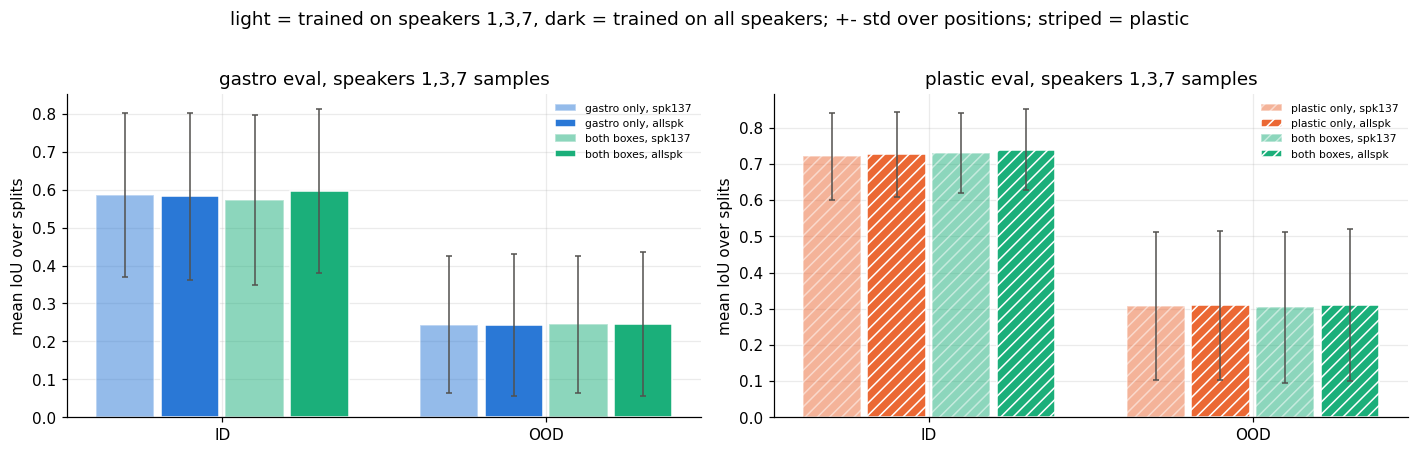

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, box in zip(axes, BOXES):
    t = kt.loc[box]
    x = np.arange(len(t))
    for j, (m, s) in enumerate([("single", "spk137"), ("single", "allspk"), ("both", "spk137"), ("both", "allspk")]):
        c = COLOR[box] if m == "single" else COLOR["both"]
        sd = [same[(same.box == box) & (same.kind == k) & (same.model == m) & (same.setting == s)].groupby(["split", "position_id"]).iou.mean().std() for k in t.index]
        ax.bar(x + (j - 1.5) * 0.2, t[(m, s)], 0.18, color=c, hatch=HATCH[box], edgecolor="white", alpha=0.5 if s == "spk137" else 1.0,
               label=f"{LABEL[box] if m == 'single' else LABEL['both']}, {s}")
        ax.errorbar(x + (j - 1.5) * 0.2, t[(m, s)], yerr=sd, **ERR)
    ax.set_xticks(x, t.index); ax.set_ylabel("mean IoU over splits"); ax.set_title(f"{box} eval, speakers 1,3,7 samples")
    ax.legend(frameon=False, fontsize=7)
fig.suptitle("light = trained on speakers 1,3,7, dark = trained on all speakers; +- std over positions; striped = plastic", y=1.02); fig.tight_layout(); plt.show()

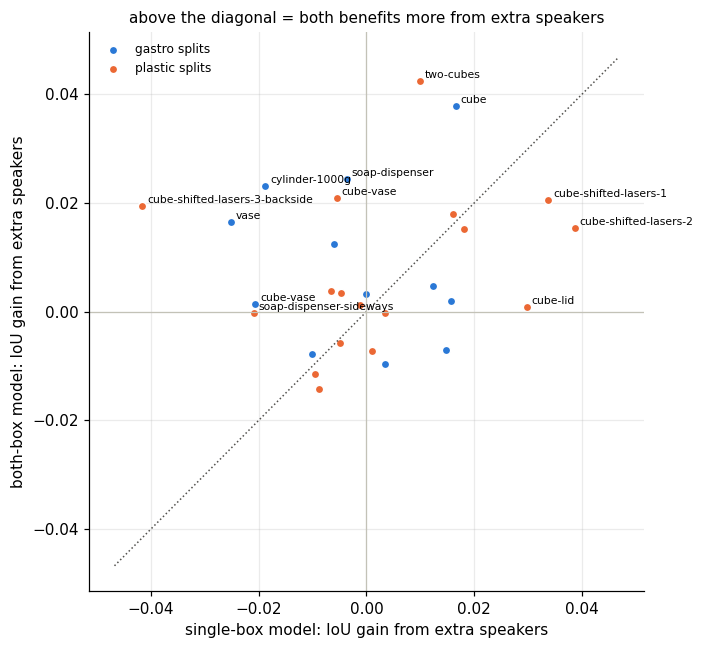

single gain  both gain
box     kind split                                                 
gastro  ID   candle                               -0.006      0.012
             cube                                  0.017      0.038
             soap-dispenser                       -0.004      0.024
             vase                                 -0.025      0.017
        OOD  coffee-pot                            0.015     -0.007
             cube-lid                              0.012      0.005
             cube-vase                            -0.021      0.001
             cylinder-1000g                       -0.019      0.023
             cylinder-100g                        -0.000      0.003
             cylinder-500g                         0.016      0.002
             soap-dispenser-sideways              -0.010     -0.008
             two-cubes                             0.004     -0.010
plastic ID   candle                               -0.007      0.004
             cube                                  0.016      0.018
             soap-dispenser                        0.018      0.015
             vase                                 -0.001      0.001
        OOD  coffee-pot                           -0.005     -0.006
             cube-lid                              0.030      0.001
             cube-shifted-lasers-1                 0.034      0.021
             cube-shifted-lasers-2                 0.039      0.015
             cube-shifted-lasers-3-backside       -0.042      0.019
             cube-vase                            -0.005      0.021
             cylinder-1000g                        0.004     -0.000
             cylinder-100g                        -0.005      0.003
             cylinder-200g                         0.001     -0.007
             cylinder-500g                        -0.009     -0.014
             portable-charger                     -0.009     -0.012
             soap-dispenser-sideways              -0.021     -0.000
             two-cubes                             0.010      0.043

In [32]:
# per split: gain from extra speakers, single vs both
g = pd.DataFrame({"single gain": tab[("single", "allspk")] - tab[("single", "spk137")],
                  "both gain": tab[("both", "allspk")] - tab[("both", "spk137")]})
fig, ax = plt.subplots(figsize=(6.5, 6))
for box in BOXES:
    gb = g.loc[box]
    ax.scatter(gb["single gain"], gb["both gain"], color=COLOR[box], s=30, label=f"{box} splits", edgecolor="white")
    for (k, s), r in gb.iterrows():
        if max(abs(r["single gain"]), abs(r["both gain"])) > 0.02: ax.annotate(s, (r["single gain"], r["both gain"]), fontsize=7, xytext=(3, 2), textcoords="offset points")
lim = np.nanmax(np.abs(g.values)) * 1.1
ax.plot([-lim, lim], [-lim, lim], color="#52514e", lw=1, ls=":"); ax.axhline(0, color="#c3c2b7", lw=0.8); ax.axvline(0, color="#c3c2b7", lw=0.8)
ax.set_xlabel("single-box model: IoU gain from extra speakers"); ax.set_ylabel("both-box model: IoU gain from extra speakers")
ax.set_title("above the diagonal = both benefits more from extra speakers", fontsize=10); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()
g.round(3)

## 6.1 The held-out speaker

In spk137, speaker 4 is never trained on, and `cube-unseen-speaker-unseen` scores it at 35 gastro and 40 plastic positions. `cube-unseen-speaker-baseline` gives the trained speakers at the same positions. The gap between the two is the cost of a new speaker. Does a model trained on two boxes generalize to a new speaker better?

In [33]:
u = matched("spk137")
u = u[u.split.str.startswith("cube-unseen-speaker")]
ut = u.groupby(["box", "model", "split"]).iou.mean().unstack("split")
ut["new-speaker cost"] = ut["cube-unseen-speaker-unseen"] - ut["cube-unseen-speaker-baseline"]
ut.round(3)

split           cube-unseen-speaker-baseline  cube-unseen-speaker-unseen  new-speaker cost
box     model                                                                             
gastro  both                           0.360                       0.134            -0.226
        single                         0.352                       0.118            -0.234
plastic both                           0.694                       0.628            -0.066
        single                         0.699                       0.610            -0.089

# 7 Big Picture

**1. Matched on samples, a second box is roughly free on ID and neutral on OOD.** In spk137 and in section 6's sample-matched allspk view, ID moves by at most 0.014 in either direction, and OOD by at most 0.004. Training one model on both boxes does not dilute it, even though each box gets only part of that model's training. Run to the end (allspk at ep2000, section 5), `both` comes out ahead on ID (+0.014 gastro, +0.011 plastic).

**2. More data tips it from a small cost to a small gain.** On the identical speaker-1,3,7 samples (section 6), adding the other speakers changes gastro ID by -0.005 for gastro-only but **+0.023 for `both`**, and plastic ID by +0.007 vs +0.009. As a result, `both` minus single on gastro ID goes from -0.013 (spk137) to +0.014 (allspk). The shared model seems to have spare capacity that extra speakers fill. Single seed, but the effect is consistent across ID splits.

**3. "Crisper and more confident" comes from extra training.** At ep2000 (section 5), `both` has seen 2-2.7x the samples and is slightly more decisive (fewer unsure pixels on every kind). At matched samples (spk137) its ID masks are, if anything, slightly blurrier. Calibration is identical either way. The robust confidence effect is that **`both` hedges more on unfamiliar plastic inputs**: a lower highest pixel on plastic OOD at both matchings.

**4. It reduces the new-speaker penalty on plastic but not on gastro.** The cost of an unseen speaker shrinks from -0.089 to -0.066 on plastic. On gastro it is barely changed (-0.234 vs -0.226). Gastro's speaker gap is much larger and is not a box-sharing problem.

**5. One cost shows up in every comparison: plastic two-object scenes get merged.** `both` turns them into one blob 27-31% of the time vs 18-24%. Plastic soap-dispenser-sideways and the portable charger also lose in both settings. Those are the cases to watch if more boxes are added.